# 32130 Assignment 3 - Predicting `Diabetes_binary`

**Classification - Student ID 26314132**

This notebook holds every computation, table and figure used in the Assignment 3 report. It follows on from the Assignment 2 exploration (`fda_a2_26314132_analysis.ipynb`), but runs on a different, larger extract (`training_90.csv`, 63,622 rows), so every number here is recomputed. None are carried over from Assignment 2.

| Section | Contents | Report section |
|---|---|---|
| §1 | Setup, run options, chart style | - |
| §2 | Integrity checks and the `pid` leak | 1, 2 |
| §3 | The hold-out split | 3 |
| §4 | What separates the classes (training rows only) | 1, 2 |
| §5 | Pre-processing: encoding, scaling, binning | 2 |
| §6 | Evaluation protocol and baselines | 3 |
| §7 | One tuned classifier per method (7.1 to 7.8) | 4 |
| §8 | Comparing the classifiers and choosing one | 4, 5 |
| §9 | Does removing the low-variation attributes help? | 2, 5 |
| §10 | Final, one-off test of the chosen classifier | 5 |
| §11 | Decision threshold and real-world prevalence | 5 |
| §12 | How the chosen classifier makes its decisions | 5 |
| §13 | Export of every number the report quotes | - |

**Ground rules.** (1) The test set is set aside in §3 and is not used again until §10. Every tuning and selection decision before that uses cross-validation on the training rows only. (2) Every pre-processing step sits inside a scikit-learn `Pipeline`, so scalers, encoders and binning are fitted again on each training fold and never see the fold being scored. (3) Every number the report quotes is printed by a cell here and exported in §13.

## §1 Setup

**Running on Colab:** put `training_90.csv` in a Drive folder called `fda_a3` (so the path is `MyDrive/fda_a3/training_90.csv`). Outputs, figures and cached search results are written into that folder.

`FORCE_RERUN = False` reuses cached search results, which lets the whole notebook replay in a few minutes (useful in the oral defence). Set it to `True` to redo every search from scratch. On a 2-core machine like free Colab, the first full run takes about 75 minutes, about 25 of them for the k-NN search.

In [1]:
import os, re, sys, time, json, warnings
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/fda_a3'
else:
    BASE = os.environ.get('FDA_A3_BASE', '.')

DATA_PATH = os.path.join(BASE, 'training_90.csv')
FIG_DIR   = os.path.join(BASE, 'figs');    os.makedirs(FIG_DIR, exist_ok=True)
OUT_DIR   = os.path.join(BASE, 'outputs'); os.makedirs(OUT_DIR, exist_ok=True)
CACHE_DIR = os.path.join(BASE, 'cache');   os.makedirs(CACHE_DIR, exist_ok=True)

FORCE_RERUN = False      # True = redo every search; False = reuse cached results where present
RS = 42                  # one random seed for every split, search and model
print('Data :', DATA_PATH)

Data : /tmp/claude-0/-home-claude/c9b9a1fe-4c12-534d-95e5-eee87b3c50aa/scratchpad/run/training_90.csv


In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import joblib
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_validate, cross_val_predict,
                                     validation_curve, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   OneHotEncoder, FunctionTransformer)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.svm import LinearSVC, SVC
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, roc_curve, brier_score_loss)
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning
from scipy.stats import loguniform, randint
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)  # majority-class baseline never predicts 1

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
SK_VER = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


In [3]:
import matplotlib as mpl, matplotlib.pyplot as plt
# Same palette as Assignment 2 so figures read as one body of work
INK, MUTED, RULE = '#1F2933', '#7B8794', '#E4E7EB'
BLUE, BLUE_LT, AMBER, RED, GREEN = '#2F6F9F', '#9EC5DF', '#D98A2B', '#BF4342', '#4E8C6A'
SEQ = [BLUE, AMBER, GREEN, RED, BLUE_LT, MUTED, '#7A5C99', '#3E8E8E', '#B07D48', '#5B6770']
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'figure.facecolor': 'white',
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'axes.titlesize': 11.5,
    'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': RULE, 'grid.linewidth': .8, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'font.size': 9.5, 'legend.frameon': False})

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')

def safe(name):
    """File-system-safe version of a model name, e.g. 'Ensemble: stacking' -> 'Ensemble_stacking'."""
    return re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_')

def cached(name, fn):
    """Run fn() once and store its (small) result; replay it on later runs unless FORCE_RERUN."""
    path = os.path.join(CACHE_DIR, f'{safe(name)}.joblib')
    if os.path.exists(path) and not FORCE_RERUN:
        try:
            return joblib.load(path)
        except Exception as e:          # e.g. cache written by a different scikit-learn version
            print(f'  cache for {name} unreadable ({type(e).__name__}); recomputing')
    t0 = time.time(); out = fn(); out['seconds'] = time.time() - t0
    joblib.dump(out, path, compress=3)
    return out

### §1.1 Attribute groups

These are the same groups used in Assignment 2. The measurement scale decides which pre-processing each attribute gets in §5.

In [4]:
TARGET  = 'Diabetes_binary'
BINARY  = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
           'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
           'NoDocbcCost', 'DiffWalk', 'Sex_male']           # Sex is recoded in §2.3
ORDINAL = ['GenHlth', 'Age', 'Education', 'Income']
RATIO   = ['BMI', 'MentHlth', 'PhysHlth']
FEATURES = BINARY + ORDINAL + RATIO
LOW_VARIATION = ['CholCheck', 'AnyHealthcare', 'HvyAlcoholConsump', 'Stroke']  # flagged in A2 §1A.2.4
# Category sets come from the data dictionary, not from the data, so an unseen level can never break a model
ORD_LEVELS = {'GenHlth': list(range(1, 6)), 'Age': list(range(1, 14)),
              'Education': list(range(1, 7)), 'Income': list(range(1, 9))}
print(len(FEATURES), 'candidate predictors:', len(BINARY), 'binary,', len(ORDINAL), 'ordinal,', len(RATIO), 'ratio')

21 candidate predictors: 14 binary, 4 ordinal, 3 ratio


## §2 Integrity checks

### §2.1 Structure, ranges, class balance

In [5]:
raw = pd.read_csv(DATA_PATH)
N = len(raw)
print('Rows, columns         :', raw.shape)
print('Null cells            :', int(raw.isna().sum().sum()))
print('Duplicate pid values  :', int(raw.pid.duplicated().sum()))
legal = {**{c: {0, 1} for c in BINARY if c != 'Sex_male'}, TARGET: {0, 1},
         **{c: set(v) for c, v in ORD_LEVELS.items()},
         'MentHlth': set(range(31)), 'PhysHlth': set(range(31))}
bad = {c: sorted(set(raw[c].unique()) - ok) for c, ok in legal.items() if set(raw[c].unique()) - ok}
print('Out-of-range codes    :', bad if bad else 'none')
print('BMI min / max         :', raw.BMI.min(), '/', raw.BMI.max(), '(dictionary allows 12-98)')
print('Sex values            :', sorted(raw.Sex.unique()))
print()
vc = raw[TARGET].value_counts().sort_index()
print('Class counts          :', vc.to_dict(), f'-> {vc[1]/N:.2%} positive')

Rows, columns         : (63622, 23)
Null cells            : 0
Duplicate pid values  : 0
Out-of-range codes    : none
BMI min / max         : 12 / 98 (dictionary allows 12-98)
Sex values            : ['female', 'male']

Class counts          : {0: 31811, 1: 31811} -> 50.00% positive


The classes are split exactly 50/50. A survey sample does not come out that way by chance, which confirms what Assignment 2 found: this is the deliberately balanced version of the BRFSS 2015 Diabetes Health Indicators data. Two consequences follow. First, **accuracy is a fair metric here**, because always guessing one class scores only 50%. Second, **the 50% base rate is artificial**. In the full, unbalanced BRFSS file about 13.9% of respondents are positive (35,346 of 253,680), so precision measured on this file overstates real-world precision. §11 corrects for that.

### §2.2 The `pid` leak

Assignment 2 treated `pid` as a meaningless record key. That needs testing rather than assuming, because an ID can carry information about how a file was put together.

In [6]:
print(raw.groupby(TARGET).pid.agg(['min', 'max', 'count']))
cut = raw.loc[raw[TARGET] == 0, 'pid'].max()
leak_acc = ((raw.pid > cut).astype(int) == raw[TARGET]).mean()
print(f'\nRule "pid > {cut} -> diabetic" is correct for {leak_acc:.4%} of rows')
leak_cv = cross_validate(DecisionTreeClassifier(max_depth=1, random_state=RS), raw[['pid']], raw[TARGET],
                         cv=StratifiedKFold(5, shuffle=True, random_state=RS), scoring='accuracy')
print(f'A depth-1 tree given only pid: CV accuracy {leak_cv["test_score"].mean():.4f}')

                   min    max  count
Diabetes_binary                     
0                    1  35346  31811
1                35347  70690  31811

Rule "pid > 35346 -> diabetic" is correct for 100.0000% of rows
A depth-1 tree given only pid: CV accuracy 1.0000


`pid` separates the classes **perfectly**. Every non-diabetic has a pid of 35,346 or below and every diabetic has a higher one. The source file was sorted by class before the ids were assigned, so `pid` records *which half of the file a row came from*, and that is the label itself. A model allowed to see it would score 100% and be useless on any new person, who would not come with a pid that encodes their diagnosis. **`pid` is excluded from every model.** This is target leakage. It is invisible in a correlation table of the health attributes and only shows up if the identifier is tested too.

### §2.3 Recoding `Sex` and checking for duplicate answer profiles

In [7]:
df = raw.drop(columns='pid').copy()
df['Sex_male'] = (df.pop('Sex') == 'male').astype(int)   # same coding as A2 §1B.4: male = 1
X_all, y_all = df[FEATURES], df[TARGET]

dup_rows = int(df.duplicated().sum())
prof = df.groupby(FEATURES)[TARGET].agg(['size', 'nunique'])
conflict_rows = int(prof.loc[prof['nunique'] > 1, 'size'].sum())
print(f'Distinct answer profiles       : {len(prof):,} of {N:,} rows')
print(f'Redundant exact duplicate rows : {dup_rows:,} ({dup_rows/N:.2%})')
print(f'Rows whose exact profile also appears with the OTHER label: {conflict_rows:,} ({conflict_rows/N:.2%})')

Distinct answer profiles       : 61,908 of 63,622 rows
Redundant exact duplicate rows : 1,365 (2.15%)
Rows whose exact profile also appears with the OTHER label: 836 (1.31%)


Duplicates are **kept**. With 14 yes/no answers and a handful of coarse scales, two different people can easily give identical answers. Each duplicate row is a separate pid, so these are separate respondents, not repeated records, and deleting them would distort the sample. The **conflicting** profiles matter more. Those people gave identical answers to every question yet sit in opposite classes, so no classifier can get all of them right. They give a first sign that the achievable accuracy has a ceiling well below 100%.

## §3 The hold-out split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20,
                                                    stratify=y_all, random_state=RS)
print('Training:', X_train.shape, '| positive share', round(y_train.mean(), 4))
print('Test    :', X_test.shape,  '| positive share', round(y_test.mean(), 4))
train_profiles = set(map(tuple, X_train.values))
in_train = np.array([tuple(r) in train_profiles for r in X_test.values])
print(f'Test rows whose exact answer profile also occurs in training: {in_train.sum():,} ({in_train.mean():.2%})')

Training: (50897, 21) | positive share 0.5
Test    : (12725, 21) | positive share 0.5
Test rows whose exact answer profile also occurs in training: 492 (3.87%)


**Why 80/20 plus cross-validation, and not a single train/validation/test split.**

* The **20% test set (12,725 rows) is locked away until §10.** It is used once, to estimate how the chosen model performs on unseen people. Because it plays no part in any choice, its score is an unbiased estimate. `training_90.csv` is itself 90% of the source file, so the marker probably holds the remaining 10% (about 7,070 rows). This internal test set imitates that.
* **Hyper-parameters are chosen by 5-fold stratified cross-validation on the 50,897 training rows.** Every row is used for validation exactly once, and each setting gets five scores instead of one. That shows how much a score varies between folds as well as its average, and this variation is what §8 needs to tell a real difference between classifiers from noise. A single validation split would give one number per setting with no measure of its reliability.
* **Stratified** sampling keeps every fold at exactly 50/50.
* Every classifier is scored on **the same five folds** (fixed `random_state`). That makes the comparison *paired*: fold 3 is equally easy or hard for every model, so differences between models are not mixed up with differences between folds.

The overlap check above counts test rows whose exact answer profile also appears in training. A model can partly recognise those rows rather than generalise to them. The share is printed above. It is small, and with many distinct people sharing common profiles this is a normal property of survey data, not leakage.

## §4 What separates the classes (training rows only)

This is a quick recheck on the new extract of the relationships Assignment 2 found. It uses training rows only, so nothing learned here comes from the test set. Mutual information measures how much knowing an attribute reduces uncertainty about the class. It needs no assumption about scale or straight-line shape, so it suits the mix of yes/no, ranked and measured attributes here.

In [9]:
tr = X_train.assign(**{TARGET: y_train})
disc = np.array([c not in RATIO for c in FEATURES])
mi = pd.Series(mutual_info_classif(X_train, y_train, discrete_features=disc, random_state=RS),
               index=FEATURES).sort_values(ascending=False)
prof_tab = pd.DataFrame({
    'non-diabetic mean / share': tr[tr[TARGET] == 0][FEATURES].mean(),
    'diabetic mean / share':     tr[tr[TARGET] == 1][FEATURES].mean()})
prof_tab['difference'] = prof_tab.iloc[:, 1] - prof_tab.iloc[:, 0]
prof_tab['mutual information (bits)'] = mi / np.log(2)
prof_tab = prof_tab.loc[mi.index]
print(prof_tab.round(4).to_string())

                      non-diabetic mean / share  diabetic mean / share  difference  mutual information (bits)
GenHlth                                  2.3891                 3.2904      0.9014                     0.1316
HighBP                                   0.3757                 0.7548      0.3791                     0.1084
BMI                                     27.7882                31.9033      4.1151                     0.0798
Age                                      7.7929                 9.3807      1.5879                     0.0675
HighChol                                 0.3831                 0.6709      0.2879                     0.0608
DiffWalk                                 0.1349                 0.3731      0.2382                     0.0557
PhysHlth                                 3.7164                 8.0272      4.3108                     0.0411
Income                                   6.1739                 5.2087     -0.9652                     0.0395
HeartDisea

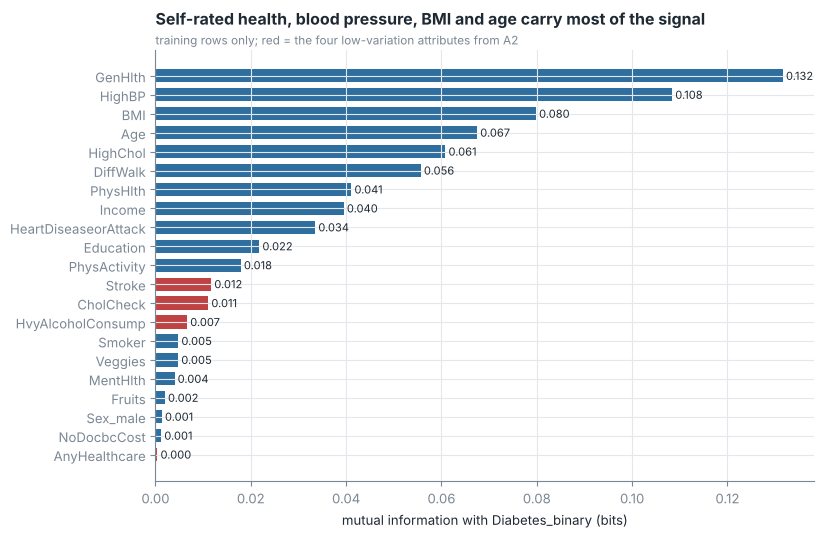

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
v = (mi / np.log(2)).iloc[::-1]
cols = [RED if c in LOW_VARIATION else BLUE for c in v.index]
ax.barh(v.index, v.values, color=cols, height=.7)
for i, val in enumerate(v.values):
    ax.text(val, i, f' {val:.3f}', va='center', fontsize=8, color=INK)
ax.set_xlabel('mutual information with Diabetes_binary (bits)')
ax.set_title('Self-rated health, blood pressure, BMI and age carry most of the signal', pad=18)
ax.text(0, 1.012, 'training rows only; red = the four low-variation attributes from A2',
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
savefig(fig, 'a3_fig1_mutual_information.png'); plt.show()

**Reading the result.** On the new rows the ranking confirms the main relationships found in A2. Self-rated health (0.132 bits), high blood pressure (0.108), BMI (0.080) and age (0.067) lead. PhysHlth carries some information (0.041) but MentHlth almost none (0.004). Two of the four "low-variation" attributes, Stroke (0.012) and CholCheck (0.011), each tell us more about the class than Smoker, Veggies, Fruits or MentHlth. Rarity limits how much an attribute *can* say, not whether it says anything. §9 tests this properly.

## §5 Pre-processing

Different classifiers need different treatment. Each pre-processor below is built as a `ColumnTransformer` and used *inside* a pipeline, so it is fitted again on every training fold.

| Classifier family | Needs | Pre-processing used |
|---|---|---|
| Trees, Random Forest, Gradient Boosting | Nothing. Splits depend only on the order of values | Raw integer codes. Ordinals keep their order |
| k-NN, SVM, Neural Network | Comparable scales, because they work with distances or weighted sums | Measured and ranked attributes rescaled. Yes/no left as 0/1 |
| Logistic Regression | Comparable scales for the penalty, plus an encoding choice | Ordinal-as-number **or** one-hot categories (tuned as a hyper-parameter) |
| Naive Bayes | A distribution assumption per attribute | Gaussian on raw values **or** categorical on binned values (both tried) |

**Why yes/no attributes are not rescaled.** Standardising a rare flag gives its "yes" a very large value. `Stroke` is about 6% yes, so a yes would become roughly +4 standard deviations, and a single rare answer would dominate any distance calculation. Kept as 0/1, every yes/no attribute contributes at most 1 unit, on the same footing as one standard deviation of BMI.

In [11]:
def prep_scaled(scaler=None):
    """Rescale measured + ranked attributes; pass yes/no through as 0/1."""
    return ColumnTransformer([('num', scaler if scaler is not None else StandardScaler(), ORDINAL + RATIO),
                              ('bin', 'passthrough', BINARY)])

def prep_onehot():
    """Ranked attributes as unordered categories (one column per level, first level dropped)."""
    return ColumnTransformer([('ord', OneHotEncoder(categories=[ORD_LEVELS[c] for c in ORDINAL],
                                                    drop='first', handle_unknown='ignore'), ORDINAL),
                              ('num', StandardScaler(), RATIO),
                              ('bin', 'passthrough', BINARY)])

# Binning for categorical Naive Bayes. Cut points come from domain thresholds and from what A2 found,
# not from the data, so the bins are fixed in advance and identical in every fold.
BMI_CUTS  = [18.5, 25, 30, 35, 40]          # WHO/CDC adult bands: under, healthy, over, obese I, II, III
DAYS_CUTS = [1, 6, 15, 30]                  # 0 | 1-5 | 6-14 | 15-29 | 30 (every day)
def to_categories(X):
    X = pd.DataFrame(X, columns=FEATURES)
    out = pd.DataFrame(index=X.index)
    for c in BINARY:  out[c] = X[c].astype(int)
    for c in ORDINAL: out[c] = X[c].astype(int) - 1                      # 0-based codes
    out['BMI'] = np.digitize(X['BMI'], BMI_CUTS)
    for c in ['MentHlth', 'PhysHlth']: out[c] = np.digitize(X[c], DAYS_CUTS)
    return out.values
N_CATS = [2] * len(BINARY) + [len(ORD_LEVELS[c]) for c in ORDINAL] + [6, 5, 5]
prep_binned = lambda: FunctionTransformer(to_categories)

### §5.1 The bins used for Naive Bayes, with their counts

Assignment 2 feedback asked for binning conclusions that match the counts reported, so the counts and diabetes rates are printed straight from the training rows.

* **BMI** uses the standard adult bands rather than equal-width or equal-frequency cuts. The thresholds have a clinical meaning and do not depend on this sample.
* **MentHlth / PhysHlth** use 0, 1-5, 6-14, 15-29 and 30. Zero gets its own bin because most people sit there. 30 gets its own bin because it is the ceiling of the question, and A2 showed it marks a distinct always-unwell group rather than the end of a smooth tail. The middle cuts fall just after the round numbers people report (5, 14/15).

In [12]:
BIN_LABELS = {'BMI': ['<18.5', '18.5-24.9', '25-29.9', '30-34.9', '35-39.9', '40+'],
              'MentHlth': ['0', '1-5', '6-14', '15-29', '30'], 'PhysHlth': ['0', '1-5', '6-14', '15-29', '30']}
cats = pd.DataFrame(to_categories(X_train), columns=FEATURES, index=X_train.index)
bin_tables = {}
for c in RATIO:
    t = (pd.DataFrame({'bin': cats[c].map(dict(enumerate(BIN_LABELS[c]))), 'y': y_train})
           .groupby('bin', sort=False)['y'].agg(n='size', diabetic_rate='mean')
           .reindex(BIN_LABELS[c]))
    t['share_of_rows'] = t['n'] / len(cats)
    bin_tables[c] = t
    print(c); print(t.round(4).to_string()); print()

BMI
               n  diabetic_rate  share_of_rows
bin                                           
<18.5        479         0.2735         0.0094
18.5-24.9  10400         0.2738         0.2043
25-29.9    17419         0.4443         0.3422
30-34.9    12449         0.5942         0.2446
35-39.9     5828         0.6944         0.1145
40+         4322         0.7608         0.0849

MentHlth
           n  diabetic_rate  share_of_rows
bin                                       
0      34654         0.4871         0.6809
1-5     7799         0.4597         0.1532
6-14    2632         0.5338         0.0517
15-29   2718         0.5839         0.0534
30      3094         0.6438         0.0608

PhysHlth
           n  diabetic_rate  share_of_rows
bin                                       
0      28578         0.4189         0.5615
1-5     9466         0.4996         0.1860
6-14    3723         0.6132         0.0731
15-29   3332         0.6945         0.0655
30      5798         0.7161         0.113

**Reading the result.** The diabetic rate climbs at every BMI band above healthy: 27.4% for 18.5–24.9 (10,400 rows), 44.4% for 25–29.9, 59.4%, 69.4%, and 76.1% for 40+ (4,322 rows). The 479 underweight respondents sit at 27.4%, the same as the healthy band. PhysHlth rises in the same steady way, from 41.9% at 0 days (28,578 rows, 56.2%) to 71.6% at 30 days (5,798 rows). MentHlth is weaker and *not* monotonic: 1–5 bad days (46.0%) sits slightly below 0 days (48.7%) before rising to 64.4% at 30.

### §5.2 How the three scalers treat outliers and new values

Assignment 2 feedback asked for a more accurate account of how normalisation deals with outliers and with values not seen before. The cell below fits each scaler on the training rows. It then shows where the training extremes land and where a **new** person with a BMI of 105 (above anything in training) and 30 bad mental-health days would land.

In [13]:
probe = pd.DataFrame({'BMI': [X_train.BMI.median(), X_train.BMI.max(), 105], 'MentHlth': [0, 30, 30],
                      'PhysHlth': [0, 30, 30]}, index=['median person', 'training maximum', 'NEW: BMI 105'])
rows = []
for name, sc in [('MinMax', MinMaxScaler()), ('Standard (z)', StandardScaler()), ('Robust (median/IQR)', RobustScaler())]:
    sc.fit(X_train[RATIO])
    t = pd.DataFrame(sc.transform(probe[RATIO]), columns=RATIO, index=probe.index)
    t.insert(0, 'scaler', name); rows.append(t)
scale_demo = pd.concat(rows)
print(scale_demo.round(3).to_string())
print('\nTraining BMI mean / sd:', round(X_train.BMI.mean(), 3), '/', round(X_train.BMI.std(), 3),
      '| MentHlth IQR:', X_train.MentHlth.quantile(.75) - X_train.MentHlth.quantile(.25),
      '| PhysHlth IQR:', X_train.PhysHlth.quantile(.75) - X_train.PhysHlth.quantile(.25))

                               scaler     BMI  MentHlth  PhysHlth
median person                  MinMax   0.198     0.000     0.000
training maximum               MinMax   1.000     1.000     1.000
NEW: BMI 105                   MinMax   1.081     1.000     1.000
median person            Standard (z)  -0.119    -0.459    -0.581
training maximum         Standard (z)   9.590     3.222     2.387
NEW: BMI 105             Standard (z)  10.575     3.222     2.387
median person     Robust (median/IQR)   0.000     0.000     0.000
training maximum  Robust (median/IQR)   8.625    15.000     5.000
NEW: BMI 105      Robust (median/IQR)   9.500    15.000     5.000

Training BMI mean / sd: 29.846 / 7.107 | MentHlth IQR: 2.0 | PhysHlth IQR: 6.0


What the table shows, stated carefully:

* **None of the three scalers caps new values.** A transformation fitted on training data is a fixed straight-line formula, so a new BMI of 105 lands *beyond* the training range under all three: above 1 for min-max (it is **not** clipped to 0-1 unless clipping is switched on), and simply a larger z or robust score for the other two. Models that work with distances then treat that person as very far from everyone, which is correct.
* **Min-max is the most sensitive to a single extreme value.** Its range comes from just two rows, so the training maximum (BMI 98) squeezes everyone else into a narrow band near the bottom of 0-1.
* **The z-score is not outlier-proof either.** The mean and standard deviation are both pulled by extreme values (standard deviation most, because deviations are squared). It is *less* sensitive than min-max because every row contributes, not just two.
* **Robust scaling (median / IQR) ignores the extremes when it is fitted, but behaves badly on zero-inflated counts.** The IQR of MentHlth is only 2 days, because most people report 0. So 30 bad days becomes a robust score of 15, which lets the day counts dominate any distance. Robust scaling is designed for outliers in roughly bell-shaped data, not for zero-inflated data like this.

On these rows the training maximum BMI of 98 becomes 1.000 under min-max, 9.59 as a z-score and 8.63 as a robust score, while the median person sits at 0.198, −0.12 and 0. The new BMI of 105 becomes 1.081, 10.58 and 9.50. Thirty bad mental-health days become 3.22 as a z-score but 15.0 as a robust score.

These are the three candidates k-NN chooses between in §7.2, so the choice is settled by cross-validation instead of being argued in advance.

## §6 Evaluation protocol and baselines

**Primary metric: ROC-AUC**, the probability that the model ranks a randomly chosen diabetic above a randomly chosen non-diabetic. It is used for tuning and selection because it measures ranking quality at *every* threshold. The threshold is a business decision (§11), and an organisation would choose it based on what a missed case costs compared with a false alarm, so the model should be judged independently of it. **Accuracy, precision, recall (sensitivity) and F1** at the default 0.5 threshold are recorded alongside it. On this 50/50 data, accuracy is easy to interpret, and recall matters most for a screening use.

**Selection rule:** the classifier with the highest mean cross-validated ROC-AUC is the starting point. Whether its lead is *real* is checked with a corrected paired t-test (§8.2). Whether it is *large enough to matter* is checked with the one-standard-error rule (§8.3).

In [14]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
SCORING = {'roc_auc': 'roc_auc', 'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}
METRICS = list(SCORING)
REGISTRY = {}   # name -> dict(family, params, folds DataFrame, fit seconds, estimator to refit)

def slim(search):
    """Keep only what later sections need from a fitted search (not the fitted models)."""
    return {'cv_results': pd.DataFrame(search.cv_results_), 'best_params': search.best_params_,
            'best_index': int(search.best_index_)}

def folds_of(cvres, idx):
    return pd.DataFrame({m: [cvres.loc[idx, f'split{k}_test_{m}'] for k in range(CV.get_n_splits())]
                         for m in METRICS})

def register(name, family, estimator, res):
    folds = folds_of(res['cv_results'], res['best_index'])
    fit_s = float(res['cv_results'].loc[res['best_index'], 'mean_fit_time'])
    REGISTRY[name] = dict(family=family, estimator=estimator, params=res['best_params'],
                          folds=folds, fit_seconds=fit_s)
    m = folds.mean()
    print(f'{name:28s} AUC {m.roc_auc:.4f} ± {folds.roc_auc.std():.4f} | acc {m.accuracy:.4f} | '
          f'recall {m.recall:.4f} | precision {m.precision:.4f} | F1 {m.f1:.4f}')

def run_search(name, estimator, grid, randomized=False, n_iter=20, X=None, y=None, cv=None):
    def go():
        kw = dict(scoring=SCORING, refit=False, cv=cv or CV, n_jobs=-1, return_train_score=True)
        s = (RandomizedSearchCV(estimator, grid, n_iter=n_iter, random_state=RS, **kw) if randomized
             else GridSearchCV(estimator, grid, **kw))
        s.fit(X_train if X is None else X, y_train if y is None else y)
        cvr = pd.DataFrame(s.cv_results_)
        best = int(cvr['rank_test_roc_auc'].idxmin())
        return {'cv_results': cvr, 'best_params': cvr.loc[best, 'params'], 'best_index': best}
    res = cached(name, go)
    print(f'[{name}] {len(res["cv_results"])} settings x {(cv or CV).get_n_splits()} folds, '
          f'{res["seconds"]/60:.1f} min. Best: {res["best_params"]}')
    return res

def prep_name(p):
    """Readable name for a pre-processor that was tuned as a hyper-parameter."""
    names = [n for n, _, _ in p.transformers]
    return 'one-hot ordinals + standard' if 'ord' in names else type(p.transformers[0][1]).__name__

def top_settings(res, k=5, cols=None):
    cvr = res['cv_results'].sort_values('rank_test_roc_auc')
    keep = (cols or [c for c in cvr.columns if c.startswith('param_')]) + \
           ['mean_test_roc_auc', 'std_test_roc_auc', 'mean_train_roc_auc', 'mean_test_accuracy']
    return cvr[keep].head(k).round(4)

### §6.1 Baselines

Two reference points, so every later number can be read against something. **Always "no diabetes"** shows what no learning at all achieves (on 50/50 data, 50% accuracy, AUC 0.5). **One rule** is a depth-1 tree, i.e. the best single yes/no question. It shows how much of the problem one attribute solves, and anything more complex has to improve on it to be worth its cost.

In [15]:
for name, est in [('Baseline: always no diabetes', DummyClassifier(strategy='constant', constant=0)),
                  ('Baseline: one rule (stump)', DecisionTreeClassifier(max_depth=1, random_state=RS))]:
    res = run_search(safe(name), est, {}, cv=CV)
    register(name, 'Baseline', est, res)
stump = DecisionTreeClassifier(max_depth=1, random_state=RS).fit(X_train, y_train)
print('\nThe one rule found:', export_text(stump, feature_names=FEATURES).splitlines()[0].strip())

[Baseline_always_no_diabetes] 1 settings x 5 folds, 0.0 min. Best: {}
Baseline: always no diabetes AUC 0.5000 ± 0.0000 | acc 0.5000 | recall 0.0000 | precision 0.0000 | F1 0.0000
[Baseline_one_rule_stump] 1 settings x 5 folds, 0.0 min. Best: {}
Baseline: one rule (stump)   AUC 0.6895 ± 0.0050 | acc 0.6895 | recall 0.7548 | precision 0.6677 | F1 0.7085

The one rule found: |--- HighBP <= 0.50


## §7 One tuned classifier per method

Each classifier gets a search over its main hyper-parameters, scored by 5-fold CV on the same folds. Grid search is used when the grid is small enough to cover completely. Randomised search is used for the ensembles, where the space is large and Bergstra & Bengio (2012) showed random sampling finds good regions with far fewer fits. Training-fold AUC is recorded next to validation AUC so that over-fitting shows up directly.

### §7.1 Logistic Regression

Tuned: **encoding** of the ranked attributes (numeric vs one-hot), **penalty type** (`l1_ratio` 0 = ridge/L2, 1 = lasso/L1), and **penalty strength** `C` (smaller = stronger penalty). One-hot lets the model give each age band or health rating its own effect instead of forcing one straight-line slope. It tests whether the A2 conclusion that these scales are ordinal but *not* equally spaced matters for prediction.

In [16]:
lr_kw = dict(solver='saga', max_iter=4000, random_state=RS)
if SK_VER < (1, 8):
    lr_kw['penalty'] = 'elasticnet'          # older scikit-learn needs this for l1_ratio to apply
lr_pipe = Pipeline([('prep', prep_scaled()), ('clf', LogisticRegression(**lr_kw))])
lr_grid = {'prep': [prep_scaled(), prep_onehot()],
           'clf__C': [0.001, 0.01, 0.1, 1, 10],
           'clf__l1_ratio': [0.0, 1.0]}
res_lr = run_search('lr', lr_pipe, lr_grid)
register('Logistic Regression', 'Logistic Regression', lr_pipe, res_lr)
t = top_settings(res_lr, 6)
t['param_prep'] = t['param_prep'].map(prep_name)
print(t.to_string())

[lr] 20 settings x 5 folds, 1.0 min. Best: {'clf__C': 1, 'clf__l1_ratio': 1.0, 'prep': ColumnTransformer(transformers=[('ord',
                                 OneHotEncoder(categories=[[1, 2, 3, 4, 5],
                                                           [1, 2, 3, 4, 5, 6, 7,
                                                            8, 9, 10, 11, 12,
                                                            13],
                                                           [1, 2, 3, 4, 5, 6],
                                                           [1, 2, 3, 4, 5, 6, 7,
                                                            8]],
                                               drop='first',
                                               handle_unknown='ignore'),
                                 ['GenHlth', 'Age', 'Education', 'Income']),
                                ('num', StandardScaler(),
                                 ['BMI', 'MentHlth', 'PhysHlth']),
            

**Reading the result.** One-hot encoding of the ranked attributes beats treating them as numbers. Every one of the top six settings uses it. Penalty type (L1 or L2) and strength (C from 0.1 to 10) barely matter (0.8247–0.8249). With 50,897 rows and about 40 columns there is little over-fitting for a penalty to prevent. So the A2 point that age bands and health ratings are ordered but *not evenly spaced* also matters for prediction.

### §7.2 k-Nearest Neighbours

k-NN depends entirely on distances, so the scaler is tuned *first*. That is the comparison §5.2 set up. The search is staged so it stays affordable: (A) scaler at a fixed, moderate k, then (B) k and vote weighting with the winning scaler, then (C) the distance metric. A staged search can miss interactions between settings, which is a known limitation. The k curve in Figure 2 shows that the optimum is broad and flat, so the risk is small here.

In [17]:
knn_pipe = Pipeline([('prep', prep_scaled()), ('clf', KNeighborsClassifier(n_jobs=1))])
SCALERS = {'MinMax': MinMaxScaler(), 'Standard': StandardScaler(), 'Robust': RobustScaler()}
res_knnA = run_search('knn_A_scaler', knn_pipe, {'prep': [prep_scaled(s) for s in SCALERS.values()],
                                                 'clf__n_neighbors': [51]})
a = res_knnA['cv_results']
a['scaler'] = list(SCALERS)
print(a[['scaler', 'mean_test_roc_auc', 'std_test_roc_auc', 'mean_test_accuracy']].round(4).to_string(index=False))
best_scaler_name = a.loc[a.mean_test_roc_auc.idxmax(), 'scaler']
best_scaler = SCALERS[best_scaler_name]; print('-> scaler carried forward:', best_scaler_name)

[knn_A_scaler] 3 settings x 5 folds, 2.3 min. Best: {'clf__n_neighbors': 51, 'prep': ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['GenHlth', 'Age', 'Education', 'Income',
                                  'BMI', 'MentHlth', 'PhysHlth']),
                                ('bin', 'passthrough',
                                 ['HighBP', 'HighChol', 'CholCheck', 'Smoker',
                                  'Stroke', 'HeartDiseaseorAttack',
                                  'PhysActivity', 'Fruits', 'Veggies',
                                  'HvyAlcoholConsump', 'AnyHealthcare',
                                  'NoDocbcCost', 'DiffWalk', 'Sex_male'])])}
  scaler  mean_test_roc_auc  std_test_roc_auc  mean_test_accuracy
  MinMax             0.7988            0.0021              0.7270
Standard             0.8182            0.0030              0.7425
  Robust             0.8127            0.0021              0.7390
-> scaler carried forward: St

**Reading the result.** Standard (0.8182) > Robust (0.8127) > MinMax (0.7988). This is the order §5.2 predicts. Min-max squeezes BMI into a narrow band because of a single extreme row, and robust scaling inflates the zero-heavy day counts.

In [18]:
K_GRID = [5, 11, 21, 41, 61, 81, 101, 151, 201, 301]
knn_pipe_B = Pipeline([('prep', prep_scaled(best_scaler)), ('clf', KNeighborsClassifier(n_jobs=1))])
res_knnB = run_search('knn_B_k', knn_pipe_B, {'clf__n_neighbors': K_GRID, 'clf__weights': ['uniform', 'distance']})
bp = res_knnB['best_params']
res_knnC = run_search('knn_C_metric', knn_pipe_B, {'clf__n_neighbors': [bp['clf__n_neighbors']],
                                                   'clf__weights': [bp['clf__weights']], 'clf__p': [1, 2]})
register('k-NN', 'k-NN', knn_pipe_B, res_knnC)

[knn_B_k] 20 settings x 5 folds, 16.7 min. Best: {'clf__n_neighbors': 151, 'clf__weights': 'uniform'}
[knn_C_metric] 2 settings x 5 folds, 3.4 min. Best: {'clf__n_neighbors': 151, 'clf__p': 1, 'clf__weights': 'uniform'}
k-NN                         AUC 0.8216 ± 0.0031 | acc 0.7450 | recall 0.8016 | precision 0.7201 | F1 0.7587


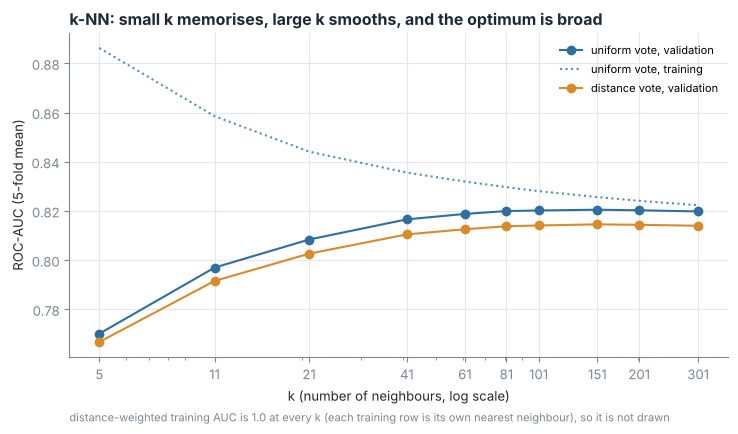

In [19]:
b = res_knnB['cv_results']
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for w, col in [('uniform', BLUE), ('distance', AMBER)]:
    s = b[b.param_weights == w] if 'param_weights' in b else b[b['param_clf__weights'] == w]
    s = s.sort_values('param_clf__n_neighbors')
    k = s['param_clf__n_neighbors'].astype(int)
    ax.plot(k, s.mean_test_roc_auc, 'o-', color=col, label=f'{w} vote, validation')
    if w == 'uniform':   # distance-weighted training AUC is 1.0 by construction (each point is its own neighbour)
        ax.plot(k, s.mean_train_roc_auc, ':', color=col, alpha=.8, label=f'{w} vote, training')
ax.set_xscale('log'); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID)
ax.set_xlabel('k (number of neighbours, log scale)'); ax.set_ylabel('ROC-AUC (5-fold mean)')
ax.set_title('k-NN: small k memorises, large k smooths, and the optimum is broad')
ax.text(0, -0.2, 'distance-weighted training AUC is 1.0 at every k (each training row is its own nearest neighbour), so it is not drawn',
        transform=ax.transAxes, color=MUTED, fontsize=8)
ax.legend(fontsize=8); savefig(fig, 'a3_fig2_knn_k_curve.png'); plt.show()

**Reading the result.** The best k-NN uses **k = 151, uniform vote, Manhattan distance (p = 1)**: CV AUC 0.8216. Validation AUC climbs steeply up to about k = 41 and is then almost flat from 61 to 301. At k = 5 the uniform model scores 0.886 on training rows but only 0.770 on validation rows, which is memorising. Distance weighting is below uniform voting at every k. With so many people sharing identical or near-identical answers, very close neighbours are not more trustworthy than slightly further ones.

### §7.3 Naive Bayes

Naive Bayes assumes every attribute is independent of every other *within each class*. A2 found clear dependencies (blood pressure with cholesterol, self-rated health with physical-health days), so this assumption is known to be broken. The model is still a useful benchmark because it is fast and very hard to over-fit. Two versions are compared:
* **Gaussian NB** on raw values. It treats every attribute, yes/no included, as bell-shaped within each class, which is a poor fit for 0/1 and zero-inflated data. Tuned: `var_smoothing`.
* **Categorical NB** on the binned values from §5.1. It estimates a probability for each category, which suits this mostly categorical data. Tuned: `alpha` (Laplace smoothing).

In [20]:
res_gnb = run_search('nb_gaussian', GaussianNB(), {'var_smoothing': np.logspace(-9, -1, 5)})
cnb_pipe = Pipeline([('prep', prep_binned()), ('clf', CategoricalNB(min_categories=N_CATS))])
res_cnb = run_search('nb_categorical', cnb_pipe, {'clf__alpha': [0.1, 1, 10]})
register('Naive Bayes (Gaussian)', 'Naive Bayes', GaussianNB(), res_gnb)
register('Naive Bayes (categorical, binned)', 'Naive Bayes', cnb_pipe, res_cnb)

[nb_gaussian] 5 settings x 5 folds, 0.0 min. Best: {'var_smoothing': np.float64(0.001)}
[nb_categorical] 3 settings x 5 folds, 0.0 min. Best: {'clf__alpha': 0.1}
Naive Bayes (Gaussian)       AUC 0.7951 ± 0.0035 | acc 0.7073 | recall 0.6387 | precision 0.7403 | F1 0.6858
Naive Bayes (categorical, binned) AUC 0.8103 ± 0.0032 | acc 0.7333 | recall 0.7280 | precision 0.7358 | F1 0.7319


**Reading the result.** Binning plus a categorical model beats the Gaussian version: AUC 0.8103 vs 0.7951, recall 0.7280 vs 0.6387. Gaussian NB has the lowest recall of any learned model because a bell curve is a poor description of 0/1 answers and zero-heavy day counts. Both NB versions still trail the other methods, which is the price of the independence assumption.

### §7.4 Decision Tree

Tuned: split **criterion**, **maximum depth** and **minimum leaf size**. The last two are the over-fitting controls. A tree grown without limits memorises the training rows. The validation curve (Figure 3) makes this visible by showing training AUC and validation AUC against depth.

In [21]:
dt = DecisionTreeClassifier(random_state=RS)
res_dt = run_search('dt', dt, {'criterion': ['gini', 'entropy'],
                               'max_depth': [3, 5, 7, 9, 11, 13, 15, None],
                               'min_samples_leaf': [1, 25, 100, 250]})
register('Decision Tree', 'Decision Tree', dt, res_dt)
print(top_settings(res_dt, 5).to_string())

[dt] 64 settings x 5 folds, 0.4 min. Best: {'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 100}
Decision Tree                AUC 0.8144 ± 0.0038 | acc 0.7402 | recall 0.7689 | precision 0.7274 | F1 0.7474
   param_criterion param_max_depth  param_min_samples_leaf  mean_test_roc_auc  std_test_roc_auc  mean_train_roc_auc  mean_test_accuracy
46         entropy               9                     100             0.8144            0.0034              0.8277              0.7402
14            gini               9                     100             0.8142            0.0028              0.8275              0.7402
50         entropy              11                     100             0.8137            0.0034              0.8298              0.7395
54         entropy              13                     100             0.8135            0.0034              0.8302              0.7395
62         entropy            None                     100             0.8135            0.0034       

Validation AUC peaks at depth 7 = 0.8116 | at depth 25: train 0.9995 valid 0.6556


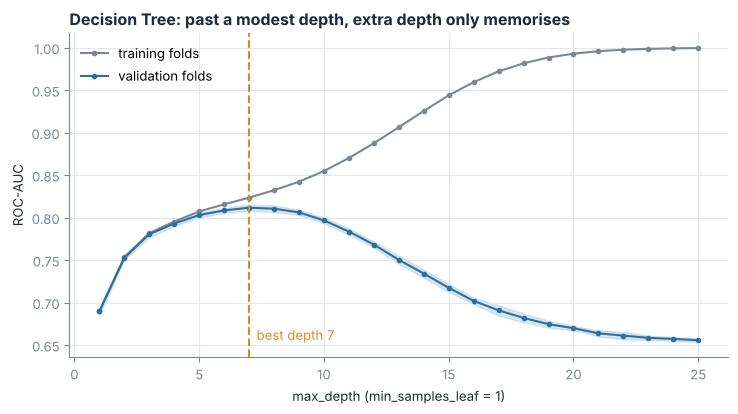

In [22]:
depths = list(range(1, 26))
def _vc():
    tr_s, va_s = validation_curve(DecisionTreeClassifier(random_state=RS), X_train, y_train,
                                  param_name='max_depth', param_range=depths, cv=CV,
                                  scoring='roc_auc', n_jobs=-1)
    return {'train': tr_s, 'valid': va_s}
vc_dt = cached('dt_validation_curve', _vc)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(depths, vc_dt['train'].mean(1), 'o-', color=MUTED, ms=3, label='training folds')
ax.plot(depths, vc_dt['valid'].mean(1), 'o-', color=BLUE, ms=3, label='validation folds')
ax.fill_between(depths, vc_dt['valid'].mean(1) - vc_dt['valid'].std(1),
                vc_dt['valid'].mean(1) + vc_dt['valid'].std(1), color=BLUE_LT, alpha=.4)
bd = depths[int(vc_dt['valid'].mean(1).argmax())]
ax.axvline(bd, color=AMBER, ls='--'); ax.text(bd + .3, ax.get_ylim()[0] + .02, f'best depth {bd}', color=AMBER)
ax.set_xlabel('max_depth (min_samples_leaf = 1)'); ax.set_ylabel('ROC-AUC')
ax.set_title('Decision Tree: past a modest depth, extra depth only memorises')
ax.legend(); savefig(fig, 'a3_fig3_tree_depth_curve.png'); plt.show()
print('Validation AUC peaks at depth', bd, '=', round(vc_dt['valid'].mean(1).max(), 4),
      '| at depth 25: train', round(vc_dt['train'].mean(1)[-1], 4), 'valid', round(vc_dt['valid'].mean(1)[-1], 4))

**Reading the result.** With no minimum leaf size, validation AUC peaks at **depth 7 (0.8116)**. Training AUC keeps rising to 0.9995 at depth 25, where validation has fallen to 0.6556: the tree is memorising individual rows. The grid's best tree (entropy, depth 9, minimum 100 rows per leaf) reaches **0.8144**. A minimum leaf size lets a slightly deeper tree stay general, because no rule can be based on fewer than 100 people.

### §7.5 Random Forest

A forest averages many deep trees, each grown on a bootstrap sample and restricted to a random subset of attributes at each split. The averaging reduces variance, which is the weakness of a single tree. **The number of trees is not tuned.** More trees cannot over-fit, they only cost time, so it is fixed at the point where the out-of-bag score stops improving (Figure 4). Tuned (randomised, 15 settings): `max_features`, `min_samples_leaf`, `max_depth`.

In [23]:
def _oob():
    rf = RandomForestClassifier(n_estimators=25, oob_score=True, warm_start=True, min_samples_leaf=5,
                                max_features='sqrt', n_jobs=-1, random_state=RS)
    sizes, oob = [25, 50, 100, 150, 200, 300, 400, 500], []
    for n in sizes:
        rf.set_params(n_estimators=n); rf.fit(X_train, y_train); oob.append(rf.oob_score_)
    return {'sizes': sizes, 'oob': oob}
oob = cached('rf_oob_curve', _oob)
print(pd.Series(oob['oob'], index=oob['sizes'], name='OOB accuracy').round(4).to_string())

25     0.7428
50     0.7471
100    0.7478
150    0.7489
200    0.7486
300    0.7486
400    0.7486
500    0.7488


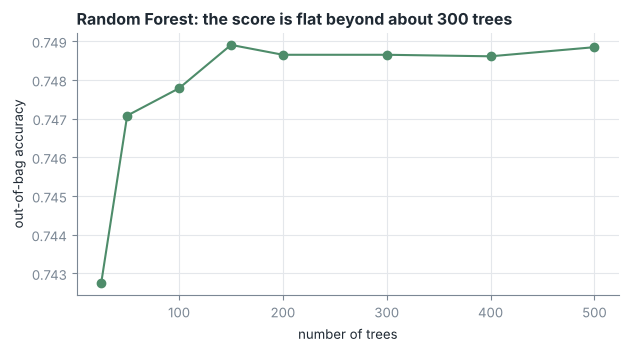

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(oob['sizes'], oob['oob'], 'o-', color=GREEN)
ax.set_xlabel('number of trees'); ax.set_ylabel('out-of-bag accuracy')
ax.set_title('Random Forest: the score is flat beyond about 300 trees')
savefig(fig, 'a3_fig4_rf_oob.png'); plt.show()

In [25]:
rf = RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RS)
res_rf = run_search('rf', rf, {'max_features': ['sqrt', 0.33, 0.5],
                               'min_samples_leaf': [1, 5, 10, 25, 50],
                               'max_depth': [None, 12, 20]}, randomized=True, n_iter=15)
register('Random Forest', 'Random Forest', rf, res_rf)
print(top_settings(res_rf, 5).to_string())

[rf] 15 settings x 5 folds, 7.6 min. Best: {'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12}
Random Forest                AUC 0.8263 ± 0.0032 | acc 0.7495 | recall 0.7940 | precision 0.7291 | F1 0.7601
    param_min_samples_leaf param_max_features param_max_depth  mean_test_roc_auc  std_test_roc_auc  mean_train_roc_auc  mean_test_accuracy
14                      10               sqrt              12             0.8263            0.0029              0.8597              0.7495
12                      10               sqrt              20             0.8260            0.0029              0.8775              0.7500
9                       25               sqrt            None             0.8256            0.0031              0.8491              0.7487
8                       25               0.33            None             0.8254            0.0031              0.8540              0.7489
0                       50               0.33              20             0.8246       

**Reading the result.** Out-of-bag accuracy reaches 0.7489 at 150 trees and is 0.7488 at 500, so 300 trees is comfortably on the flat part. The best forest (depth ≤ 12, at least 10 rows per leaf, √21 ≈ 4 attributes tried per split) is one of the more constrained settings. Training AUC is 0.8597 against validation 0.8263, and the less constrained forests did slightly worse.

### §7.6 Gradient Boosting

Boosting builds shallow trees *one after another*, each fitted to the errors the previous trees made. It reduces bias where the forest reduces variance. scikit-learn's `HistGradientBoostingClassifier` (the same algorithm family as LightGBM) is used. It bins each attribute into at most 255 values internally, which makes it fast on 50,000 rows. The number of boosting rounds is set by **early stopping**: 10% of each training fold is held back, and boosting stops once 20 rounds pass without improvement. That way the round count is chosen on data the trees are not trained on. Tuned (randomised, 30 settings): learning rate, leaves per tree, minimum leaf size, L2 penalty.

In [26]:
hgb = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                     n_iter_no_change=20, random_state=RS)
res_hgb = run_search('hgb', hgb, {'learning_rate': loguniform(0.02, 0.3),
                                  'max_leaf_nodes': [7, 15, 31, 63],
                                  'min_samples_leaf': [20, 50, 100, 200],
                                  'l2_regularization': [0.0, 0.1, 1.0, 10.0]}, randomized=True, n_iter=30)
register('Gradient Boosting', 'Gradient Boosting', hgb, res_hgb)
print(top_settings(res_hgb, 5).to_string())

[hgb] 30 settings x 5 folds, 2.5 min. Best: {'l2_regularization': 10.0, 'learning_rate': np.float64(0.04223088873920902), 'max_leaf_nodes': 7, 'min_samples_leaf': 100}
Gradient Boosting            AUC 0.8289 ± 0.0037 | acc 0.7517 | recall 0.7996 | precision 0.7297 | F1 0.7631
    param_l2_regularization  param_learning_rate  param_max_leaf_nodes  param_min_samples_leaf  mean_test_roc_auc  std_test_roc_auc  mean_train_roc_auc  mean_test_accuracy
26                     10.0               0.0422                     7                     100             0.8289            0.0033              0.8348              0.7517
9                      10.0               0.0539                    15                      50             0.8287            0.0031              0.8388              0.7502
19                      0.1               0.0879                    15                      20             0.8286            0.0031              0.8397              0.7504
22                     10.0        

**Reading the result.** The search favoured the most conservative region: **small trees (7 leaves), a slow learning rate (0.042), at least 100 rows per leaf and the strongest L2 penalty (10)**, giving CV AUC 0.8289. Training AUC is 0.8348, a gap of only 0.006 and the smallest of any flexible model. The top five settings span just 0.8285–0.8289, so the result is not sensitive to the exact values.

### §7.7 Support Vector Machine

Two kernels.
* **Linear SVM** (`LinearSVC`) on all training folds. Tuned: `C`.
* **RBF-kernel SVM** can draw curved boundaries, but fitting time grows roughly with the *square* of the number of rows. A full grid on 40,000-row folds would take hours. So `C` and `gamma` are tuned by 5-fold CV on a **stratified 10,000-row sample** of the training set. The single best setting is then cross-validated on the *full* five folds, which makes its score directly comparable with every other classifier. This is a deliberate compute trade-off, and the report should state it.

SVMs output a signed distance from the boundary, not a probability. ROC-AUC only needs a ranking, so it uses that distance directly.

In [27]:
lsvc_pipe = Pipeline([('prep', prep_scaled()), ('clf', LinearSVC(dual=False, random_state=RS))])
res_lsvc = run_search('svm_linear', lsvc_pipe, {'clf__C': [0.001, 0.01, 0.1, 1, 10]})
register('SVM (linear)', 'SVM', lsvc_pipe, res_lsvc)

[svm_linear] 5 settings x 5 folds, 0.1 min. Best: {'clf__C': 10}
SVM (linear)                 AUC 0.8226 ± 0.0036 | acc 0.7464 | recall 0.7732 | precision 0.7338 | F1 0.7530


In [28]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=10_000, stratify=y_train, random_state=RS)
svc_pipe = Pipeline([('prep', prep_scaled()), ('clf', SVC(kernel='rbf', cache_size=1000))])
res_svc_sub = run_search('svm_rbf_tuning_10k', svc_pipe, {'clf__C': [0.1, 1, 10], 'clf__gamma': [0.01, 0.03, 0.1]},
                         X=X_sub, y=y_sub)
print(top_settings(res_svc_sub, 9).to_string())

[svm_rbf_tuning_10k] 9 settings x 5 folds, 2.2 min. Best: {'clf__C': 1, 'clf__gamma': 0.01}
   param_clf__C  param_clf__gamma  mean_test_roc_auc  std_test_roc_auc  mean_train_roc_auc  mean_test_accuracy
3           1.0              0.01             0.8332            0.0109              0.8368              0.7594
6          10.0              0.01             0.8317            0.0109              0.8419              0.7606
1           0.1              0.03             0.8314            0.0101              0.8342              0.7560
4           1.0              0.03             0.8313            0.0108              0.8419              0.7591
0           0.1              0.01             0.8302            0.0106              0.8313              0.7559
2           0.1              0.10             0.8270            0.0094              0.8371              0.7553
7          10.0              0.03             0.8261            0.0100              0.8578              0.7585
5           1.0     

In [29]:
def _svc_full():
    est = svc_pipe.set_params(**res_svc_sub['best_params'])
    cvr = cross_validate(est, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1, return_train_score=True)
    row = {f'split{k}_test_{m}': cvr[f'test_{m}'][k] for k in range(5) for m in METRICS}
    row['mean_fit_time'] = cvr['fit_time'].mean()
    return {'cv_results': pd.DataFrame([row]), 'best_params': res_svc_sub['best_params'], 'best_index': 0}
res_svc = cached('svm_rbf_full_cv', _svc_full)
register('SVM (RBF kernel)', 'SVM', svc_pipe, res_svc)

SVM (RBF kernel)             AUC 0.8269 ± 0.0039 | acc 0.7504 | recall 0.8268 | precision 0.7173 | F1 0.7681


**Reading the result.** On the 10,000-row sample the best setting was **C = 1, γ = 0.01** (0.8332 there, which is *not* comparable because it comes from smaller, noisier folds). The largest γ with the largest C over-fits (training 0.9199, validation 0.8013). Cross-validated on the full folds, the RBF SVM scores **0.8269**, above the linear SVM's 0.8226. At the 0.5 cut-off it has the **highest recall of any model (0.8268)** but the lowest precision of the strong models (0.7173), because its default boundary sits further toward "diabetic". It also costs about 50 s per fold to fit, against about 2 s for gradient boosting.

### §7.8 Neural Network (multi-layer perceptron)

A feed-forward network with ReLU hidden units, trained with Adam. Tuned: **architecture** (one or two hidden layers, 32 to 128 units) and **L2 penalty** `alpha`. Early stopping holds back 10% of each training fold and stops once the validation score has not improved for 10 epochs. This is the network's equivalent of limiting tree depth. Inputs are standardised, because gradient-based training converges badly when attributes sit on very different ranges.

In [30]:
mlp_pipe = Pipeline([('prep', prep_scaled()),
                     ('clf', MLPClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                                           max_iter=300, random_state=RS))])
res_mlp = run_search('mlp', mlp_pipe, {'clf__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)],
                                       'clf__alpha': [1e-4, 1e-3, 1e-2]})
register('Neural Network (MLP)', 'Neural Network', mlp_pipe, res_mlp)
print(top_settings(res_mlp, 5).to_string())

[mlp] 12 settings x 5 folds, 1.7 min. Best: {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (32,)}
Neural Network (MLP)         AUC 0.8277 ± 0.0038 | acc 0.7516 | recall 0.8058 | precision 0.7270 | F1 0.7644
   param_clf__alpha param_clf__hidden_layer_sizes  mean_test_roc_auc  std_test_roc_auc  mean_train_roc_auc  mean_test_accuracy
8            0.0100                         (32,)             0.8277            0.0034              0.8315              0.7516
4            0.0010                         (32,)             0.8277            0.0033              0.8314              0.7514
0            0.0001                         (32,)             0.8276            0.0032              0.8316              0.7517
5            0.0010                         (64,)             0.8275            0.0036              0.8315              0.7511
1            0.0001                         (64,)             0.8274            0.0034              0.8321              0.7504


**Reading the result.** The **smallest network (one hidden layer of 32 units)** won, at 0.8277. Larger and deeper networks were no better, and alpha made almost no difference (0.8276–0.8277). The answers do not seem to hold complex interactions that extra capacity could exploit, which matches the flexible methods all landing close together.

### §7.9 Ensembles of the tuned models

Beyond one model per method: do *different kinds* of model make different mistakes that cancel out? Two combinations of the tuned Logistic Regression, Random Forest, Gradient Boosting and Neural Network are tested:
* **Soft voting**: average the four predicted probabilities.
* **Stacking**: a logistic regression learns how much to trust each model. It is trained on out-of-fold predictions, which stops it from simply rewarding whichever base model over-fitted most.

Both are scored on the same five folds as everything else.

In [31]:
def tuned(name):
    r = REGISTRY[name]
    return sklearn.base.clone(r['estimator']).set_params(**r['params'])
base = [('lr', tuned('Logistic Regression')), ('rf', tuned('Random Forest')),
        ('gb', tuned('Gradient Boosting')), ('nn', tuned('Neural Network (MLP)'))]
vote = VotingClassifier(base, voting='soft', n_jobs=1)
stack = StackingClassifier(base, final_estimator=LogisticRegression(max_iter=1000),
                           cv=StratifiedKFold(5, shuffle=True, random_state=RS + 1), n_jobs=1)
for name, est, key in [('Ensemble: soft voting', vote, 'ens_vote'), ('Ensemble: stacking', stack, 'ens_stack')]:
    res = run_search(key, est, {}, cv=CV)
    register(name, 'Ensemble', est, res)

[ens_vote] 1 settings x 5 folds, 0.8 min. Best: {}
Ensemble: soft voting        AUC 0.8292 ± 0.0037 | acc 0.7518 | recall 0.7966 | precision 0.7311 | F1 0.7624
[ens_stack] 1 settings x 5 folds, 3.3 min. Best: {}
Ensemble: stacking           AUC 0.8294 ± 0.0037 | acc 0.7521 | recall 0.7912 | precision 0.7338 | F1 0.7614


## §8 Comparing the classifiers and choosing one

### §8.1 Cross-validated results, all on the same five folds

In [32]:
summary = pd.DataFrame({
    name: {'family': r['family'],
           **{f'{m} mean': r['folds'][m].mean() for m in METRICS},
           'AUC sd': r['folds']['roc_auc'].std(),
           'fit seconds (per fold)': r['fit_seconds'],
           'tuned parameters': {k.replace('clf__', ''): (prep_name(v) if hasattr(v, 'transformers') else v)
                                for k, v in r['params'].items()}}
    for name, r in REGISTRY.items()}).T
summary = summary.sort_values('roc_auc mean', ascending=False)
num_cols = [c for c in summary.columns if c not in ('family', 'tuned parameters')]
summary[num_cols] = summary[num_cols].astype(float)
print(summary[num_cols].round(4).to_string())

                                   roc_auc mean  accuracy mean  f1 mean  precision mean  recall mean  AUC sd  fit seconds (per fold)
Ensemble: stacking                       0.8294         0.7521   0.7614          0.7338       0.7912  0.0037                 61.9142
Ensemble: soft voting                    0.8292         0.7518   0.7624          0.7311       0.7966  0.0037                 12.5703
Gradient Boosting                        0.8289         0.7517   0.7631          0.7297       0.7996  0.0037                  2.1839
Neural Network (MLP)                     0.8277         0.7516   0.7644          0.7270       0.8058  0.0038                  2.0227
SVM (RBF kernel)                         0.8269         0.7504   0.7681          0.7173       0.8268  0.0039                 50.1894
Random Forest                            0.8263         0.7495   0.7601          0.7291       0.7940  0.0032                  5.2995
Logistic Regression                      0.8249         0.7482   0.75

**Reading the result.** All twelve learned models fall between **0.7951 and 0.8294**, a spread of 0.034, and the top seven lie within 0.0045 of each other. The one-rule baseline (*has high blood pressure?*) already reaches 0.6895. Which algorithm is used matters far less than what the 21 survey answers can tell us. The conflicting-label profiles in §2.3 and the flat learning curve in §8.4 point to the same ceiling.

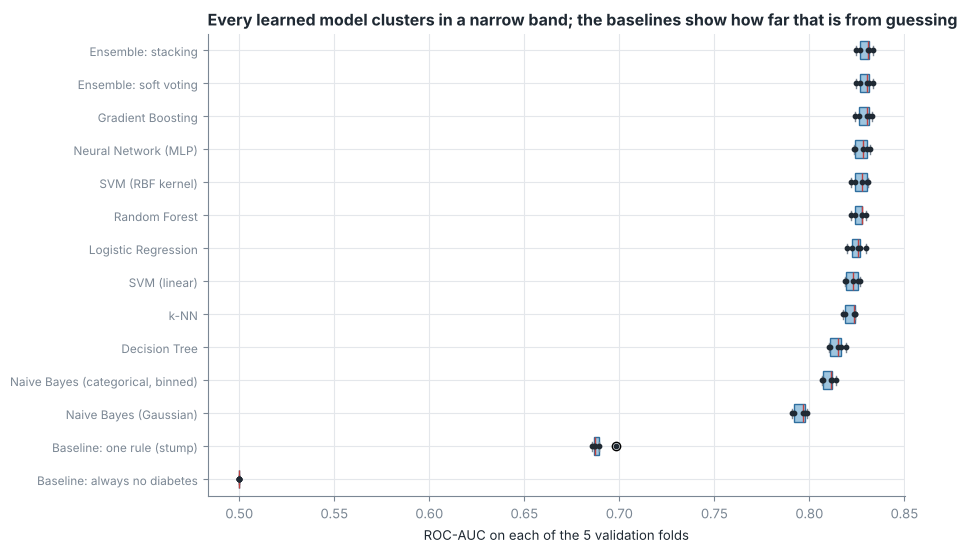

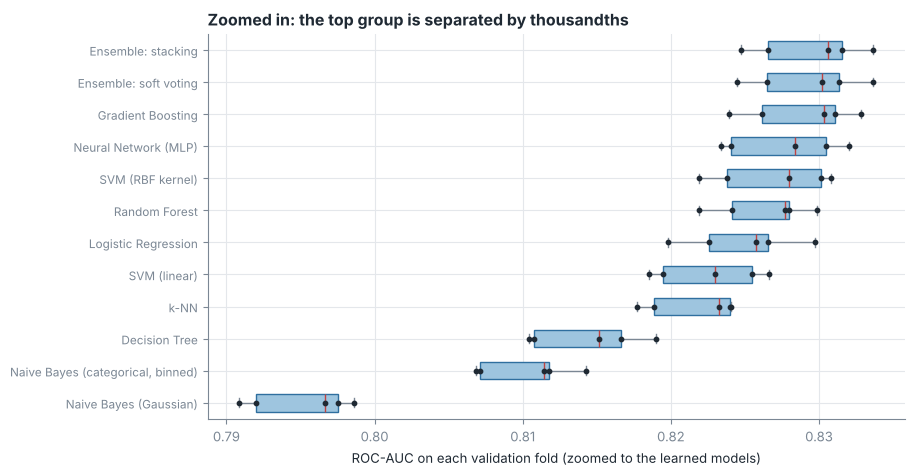

In [33]:
order = summary.index[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
data = [REGISTRY[n]['folds']['roc_auc'].values for n in order]
ax.boxplot(data, vert=False, widths=.55, patch_artist=True,
           boxprops=dict(facecolor=BLUE_LT, edgecolor=BLUE), medianprops=dict(color=RED),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for i, d in enumerate(data, start=1):
    ax.scatter(d, np.full(len(d), i), s=10, color=INK, zorder=3)
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order, fontsize=8.5)
ax.set_xlabel('ROC-AUC on each of the 5 validation folds')
ax.set_title('Every learned model clusters in a narrow band; the baselines show how far that is from guessing')
savefig(fig, 'a3_fig5_cv_comparison_all.png'); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
learned = [n for n in order if not n.startswith('Baseline')]
data = [REGISTRY[n]['folds']['roc_auc'].values for n in learned]
ax.boxplot(data, vert=False, widths=.55, patch_artist=True,
           boxprops=dict(facecolor=BLUE_LT, edgecolor=BLUE), medianprops=dict(color=RED),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for i, d in enumerate(data, start=1):
    ax.scatter(d, np.full(len(d), i), s=10, color=INK, zorder=3)
ax.set_yticks(range(1, len(learned) + 1)); ax.set_yticklabels(learned, fontsize=8.5)
ax.set_xlabel('ROC-AUC on each validation fold (zoomed to the learned models)')
ax.set_title('Zoomed in: the top group is separated by thousandths')
savefig(fig, 'a3_fig6_cv_comparison_zoom.png'); plt.show()

### §8.2 Are the differences real?

The five fold scores are not independent. The training sets of any two folds share 75% of their rows, so a plain paired t-test underestimates the variance and finds "significant" differences too easily. The **corrected resampled t-test** (Nadeau & Bengio, 2003) inflates the variance by the factor (1/k + n_test/n_train) to allow for that overlap. Each model is compared below with the top-ranked one.

In [34]:
def corrected_ttest(a, b, k=5, test_over_train=1/4):
    d = np.asarray(a) - np.asarray(b)
    se = np.sqrt((1 / k + test_over_train) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else np.inf
    return d.mean(), t, 2 * stats.t.sf(abs(t), k - 1)

leader = summary.index[0]
rows = []
for n in summary.index[1:]:
    diff, t, p = corrected_ttest(REGISTRY[leader]['folds'].roc_auc, REGISTRY[n]['folds'].roc_auc)
    wins = int((REGISTRY[leader]['folds'].roc_auc.values > REGISTRY[n]['folds'].roc_auc.values).sum())
    rows.append({'compared with': n, 'AUC gap': diff, 'leader better on folds': f'{wins}/5',
                 'corrected t': t, 'p-value': p, 'significant at 0.05': p < 0.05})
sig = pd.DataFrame(rows).set_index('compared with')
print('Leader:', leader); print(sig.round(4).to_string())

Leader: Ensemble: stacking
                                   AUC gap leader better on folds  corrected t  p-value  significant at 0.05
compared with                                                                                               
Ensemble: soft voting               0.0002                    4/5       1.4851   0.2117                False
Gradient Boosting                   0.0005                    5/5       3.3750   0.0279                 True
Neural Network (MLP)                0.0018                    5/5       4.5452   0.0105                 True
SVM (RBF kernel)                    0.0025                    5/5       6.0241   0.0038                 True
Random Forest                       0.0031                    5/5       8.4754   0.0011                 True
Logistic Regression                 0.0045                    5/5      12.2528   0.0003                 True
SVM (linear)                        0.0068                    5/5      15.5608   0.0001              

**Reading the result.** Stacking has the highest mean, but soft voting is not significantly behind it (gap 0.0002, p = 0.21). Gradient boosting is "significantly" behind by **0.0005** (p = 0.028, lower on all 5 folds). Statistically real, but tiny.

### §8.3 The choice

The cell below applies the selection rule from §6 mechanically, so the decision can be traced.

In [35]:
not_sig = sig.index[~sig['significant at 0.05']].tolist()
print(f'Highest mean CV ROC-AUC: {leader} ({summary.loc[leader, "roc_auc mean"]:.4f})')
print('Not significantly different from it:', not_sig if not_sig else 'none')
SINGLE = [n for n in summary.index if REGISTRY[n]['family'] not in ('Ensemble', 'Baseline')]
best_single = SINGLE[0]
print(f'Best single (non-ensemble) model: {best_single} ({summary.loc[best_single, "roc_auc mean"]:.4f})')

Highest mean CV ROC-AUC: Ensemble: stacking (0.8294)
Not significantly different from it: ['Ensemble: soft voting']
Best single (non-ensemble) model: Gradient Boosting (0.8289)


**Statistically significant is not the same as large enough to matter.** With 50,000 training rows and five very stable folds, the corrected t-test can detect differences far too small to change any decision. So a second test is applied: the **one-standard-error rule** (Breiman et al., 1984; Hastie, Tibshirani & Friedman, 2009, §7.10). The standard error of the leader's CV AUC is its fold standard deviation divided by √5. Any model whose mean lies within one standard error of the leader is treated as *equally good*, and among those the simplest one is chosen. "Simplest" means a single model rather than an ensemble, then the cheaper one to train and explain.

This rule was added after the comparison showed how small the gaps are. The report should say so openly rather than present it as planned from the start.

In [36]:
se_leader = REGISTRY[leader]['folds']['roc_auc'].std(ddof=1) / np.sqrt(CV.get_n_splits())
gap = summary['roc_auc mean'].iloc[0] - summary['roc_auc mean']
within = summary.index[gap <= se_leader].tolist()
print(f'Leader: {leader}  AUC {summary.loc[leader, "roc_auc mean"]:.4f}, one standard error = {se_leader:.4f}')
print('Within one standard error of the leader:')
for n in within:
    print(f'   {n:28s} gap {gap[n]:.4f} | family {REGISTRY[n]["family"]:18s} | fit seconds per fold {REGISTRY[n]["fit_seconds"]:.1f}')
singles_within = [n for n in within if REGISTRY[n]['family'] not in ('Ensemble', 'Baseline')]
CHOSEN = (min(singles_within, key=lambda n: REGISTRY[n]['fit_seconds']) if singles_within else leader)
print('\nCHOSEN =', CHOSEN, '| parameters:', REGISTRY[CHOSEN]['params'])

Leader: Ensemble: stacking  AUC 0.8294, one standard error = 0.0016
Within one standard error of the leader:
   Ensemble: stacking           gap 0.0000 | family Ensemble           | fit seconds per fold 61.9
   Ensemble: soft voting        gap 0.0002 | family Ensemble           | fit seconds per fold 12.6
   Gradient Boosting            gap 0.0005 | family Gradient Boosting  | fit seconds per fold 2.2

CHOSEN = Gradient Boosting | parameters: {'l2_regularization': 10.0, 'learning_rate': np.float64(0.04223088873920902), 'max_leaf_nodes': 7, 'min_samples_leaf': 100}


**Decision: Gradient Boosting.** One standard error of the leader's score is 0.0016. Gradient boosting is 0.0005 behind, so the rule treats it as equally good. In practical terms, stacking would add 0.0004 accuracy (0.7521 vs 0.7517), about 4 people per 10,000. That gain would cost **28× the training time** (61.9 s vs 2.2 s per fold) and four separately tuned models to maintain and explain instead of one. The test set in §10 plays no part in this choice, but it is consistent with it: the three are effectively tied there.

### §8.4 Would more data help? Learning curve of the chosen model

 rows  train AUC  valid AUC
 2035     0.8581     0.8148
 4071     0.8486     0.8214
 8143     0.8401     0.8252
16286     0.8366     0.8270
24430     0.8355     0.8277
32573     0.8356     0.8283
40717     0.8343     0.8286


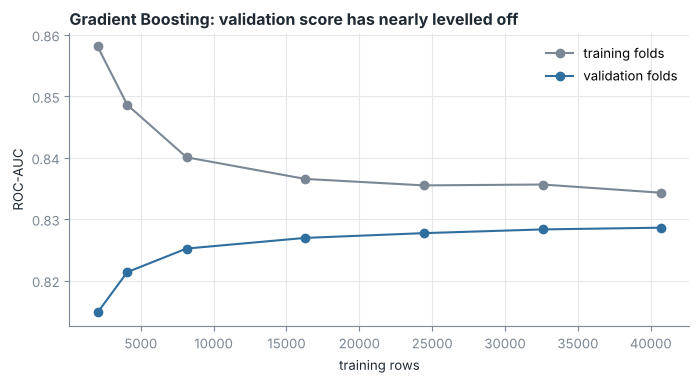

In [37]:
def _lc():
    sizes, tr_s, va_s = learning_curve(tuned(CHOSEN), X_train, y_train, cv=CV, scoring='roc_auc',
                                       train_sizes=[.05, .1, .2, .4, .6, .8, 1.0], n_jobs=-1,
                                       shuffle=True, random_state=RS)
    return {'sizes': sizes, 'train': tr_s, 'valid': va_s}
lc = cached(f'learning_curve_{CHOSEN}', _lc)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(lc['sizes'], lc['train'].mean(1), 'o-', color=MUTED, label='training folds')
ax.plot(lc['sizes'], lc['valid'].mean(1), 'o-', color=BLUE, label='validation folds')
ax.set_xlabel('training rows'); ax.set_ylabel('ROC-AUC'); ax.legend()
ax.set_title(f'{CHOSEN}: validation score has nearly levelled off')
savefig(fig, 'a3_fig7_learning_curve.png'); plt.show()
print(pd.DataFrame({'rows': lc['sizes'], 'train AUC': lc['train'].mean(1), 'valid AUC': lc['valid'].mean(1)}).round(4).to_string(index=False))

**Reading the result.** Validation AUC rises from 0.8148 with 2,035 training rows to 0.8286 with 40,717. The last two increases (about 8,000 rows each) add only 0.0006 and 0.0003. Training and validation scores have converged to within 0.006. More rows of the same survey would add very little. Better *attributes* (blood tests, family history, waist measurement) are what could lift the ceiling.

## §9 Does removing the low-variation attributes help?

Assignment 2 recommended dropping `CholCheck`, `AnyHealthcare`, `HvyAlcoholConsump` and `Stroke` because they barely vary, and the feedback asked for stronger support for that recommendation. Here it is tested directly: the chosen model and the logistic regression are each refitted with and without the four, on the same folds, and compared with the corrected t-test. Low variation does not by itself mean low predictive value. A rare answer can still be strongly linked to the class.

In [38]:
def without(cols):
    keep = [c for c in FEATURES if c not in cols]
    return ColumnTransformer([('keep', 'passthrough', keep)])

def drop_experiment(name):
    def go():
        out = {}
        for label, cols in [('all 21 attributes', []), ('without the 4 low-variation', LOW_VARIATION)]:
            est = tuned(name)
            if cols:
                # rebuild the pre-processor on the reduced column list
                if isinstance(est, Pipeline) and 'prep' in est.named_steps:
                    b2 = [c for c in BINARY if c not in cols]
                    pre = est.named_steps['prep']
                    new_tf = []
                    for n_, tf, cl in pre.transformers:
                        new_tf.append((n_, tf, [c for c in cl if c not in cols]))
                    est.set_params(prep=ColumnTransformer(new_tf))
                    if isinstance(est.named_steps['clf'], CategoricalNB):
                        raise ValueError('not used for categorical NB')
                else:
                    est = Pipeline([('sel', without(cols)), ('clf', est)])
            r = cross_validate(est, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=-1)
            out[label] = r['test_score']
        return out
    return cached(f'drop_lowvar_{name}', go)

drop_rows = []
# An ensemble inherits whatever its members use, so the test is run on the best single model and on LR
for n in dict.fromkeys([CHOSEN if REGISTRY[CHOSEN]['family'] != 'Ensemble' else best_single,
                        'Logistic Regression']):
    r = drop_experiment(n)
    a_, b_ = r['all 21 attributes'], r['without the 4 low-variation']
    diff, t, p = corrected_ttest(a_, b_)
    drop_rows.append({'model': n, 'AUC all 21': a_.mean(), 'AUC without 4': b_.mean(),
                      'change from dropping': -diff, 'p-value': p})
drop_tab = pd.DataFrame(drop_rows).set_index('model')
print(drop_tab.round(4).to_string())

                     AUC all 21  AUC without 4  change from dropping  p-value
model                                                                        
Gradient Boosting        0.8289         0.8256               -0.0033   0.0011
Logistic Regression      0.8249         0.8215               -0.0034   0.0011


**Reading the result: the A2 recommendation does not hold up.** Removing CholCheck, AnyHealthcare, HvyAlcoholConsump and Stroke **lowers** AUC by 0.0033 for gradient boosting and 0.0034 for logistic regression (p = 0.0011 for both; for gradient boosting the drop occurs on all five folds). The four should be **kept**. CholCheck shows why low variation is not the same as low information. Only 2.5% of training respondents (1,249 people) had *no* cholesterol check in five years, and just 13.1% of them are diabetic, against 50.9% of everyone else. That is plausibly because a check is how diabetes is found in the first place (detection, not cause). §12 shows CholCheck and heavy drinking ranking 6th and 7th in the chosen model's importance.

## §10 Final, one-off test of the chosen classifier

The chosen configuration is refitted on all 50,897 training rows and scored **once** on the 12,725 locked-away test rows. The other tuned models are also scored on the test set, for context only. The choice was already made in §8, and these test scores do not change it. Choosing by test score would turn the test set into a second validation set and remove the unbiased estimate.

In [39]:
def _fit_all():
    fitted, proba = {}, {}
    for n, r in REGISTRY.items():
        if r['family'] == 'Baseline':
            continue
        t0 = time.time(); m = tuned(n).fit(X_train, y_train)
        s = m.predict_proba(X_test)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(X_test)
        proba[n] = s; fitted[n] = time.time() - t0
    return {'scores': proba, 'fit_seconds': fitted}
test_out = cached('test_scores_all_models', _fit_all)
final_model = tuned(CHOSEN).fit(X_train, y_train)          # kept in memory for §11-§12
p_test = final_model.predict_proba(X_test)[:, 1]
yhat = (p_test >= 0.5).astype(int)

def metric_row(y, s, threshold=0.5, is_proba=True):
    pred = (s >= threshold).astype(int) if is_proba else (s >= 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'ROC-AUC': roc_auc_score(y, s), 'accuracy': accuracy_score(y, pred),
            'precision': precision_score(y, pred), 'recall (sensitivity)': recall_score(y, pred),
            'specificity': tn / (tn + fp), 'F1': f1_score(y, pred)}
test_tab = pd.DataFrame({n: metric_row(y_test, s, is_proba=(s.min() >= 0 and s.max() <= 1))
                         for n, s in test_out['scores'].items()}).T.sort_values('ROC-AUC', ascending=False)
print(test_tab.round(4).to_string())

                                   ROC-AUC  accuracy  precision  recall (sensitivity)  specificity      F1
Gradient Boosting                   0.8354    0.7558     0.7357                0.7983       0.7132  0.7657
Ensemble: stacking                  0.8352    0.7568     0.7403                0.7909       0.7226  0.7648
Ensemble: soft voting               0.8349    0.7564     0.7374                0.7963       0.7165  0.7657
Neural Network (MLP)                0.8335    0.7554     0.7300                0.8106       0.7003  0.7682
SVM (RBF kernel)                    0.8334    0.7547     0.7209                0.8312       0.6783  0.7721
Random Forest                       0.8315    0.7545     0.7346                0.7968       0.7122  0.7644
Logistic Regression                 0.8301    0.7507     0.7400                0.7730       0.7284  0.7562
SVM (linear)                        0.8285    0.7513     0.7408                0.7730       0.7295  0.7566
k-NN                                0

In [40]:
rng = np.random.RandomState(RS)
boot = {'ROC-AUC': [], 'accuracy': [], 'recall': [], 'precision': []}
yt = y_test.values
for _ in range(1000):
    i = rng.randint(0, len(yt), len(yt))
    boot['ROC-AUC'].append(roc_auc_score(yt[i], p_test[i])); boot['accuracy'].append(accuracy_score(yt[i], yhat[i]))
    boot['recall'].append(recall_score(yt[i], yhat[i])); boot['precision'].append(precision_score(yt[i], yhat[i]))
ci = pd.DataFrame({k: {'test estimate': {'ROC-AUC': roc_auc_score(yt, p_test), 'accuracy': accuracy_score(yt, yhat),
                                         'recall': recall_score(yt, yhat), 'precision': precision_score(yt, yhat)}[k],
                       '95% CI low': np.percentile(v, 2.5), '95% CI high': np.percentile(v, 97.5)}
                   for k, v in boot.items()}).T
cvm = REGISTRY[CHOSEN]['folds'].mean()
ci['5-fold CV mean'] = [cvm.roc_auc, cvm.accuracy, cvm.recall, cvm.precision]
print(f'{CHOSEN} on the held-out test set (1,000 bootstrap resamples):'); print(ci.round(4).to_string())
cm = confusion_matrix(y_test, yhat)
print('\nConfusion matrix (rows = actual 0/1, columns = predicted 0/1):'); print(cm)

Gradient Boosting on the held-out test set (1,000 bootstrap resamples):
           test estimate  95% CI low  95% CI high  5-fold CV mean
ROC-AUC           0.8354      0.8284       0.8421          0.8289
accuracy          0.7558      0.7481       0.7631          0.7517
recall            0.7983      0.7885       0.8075          0.7996
precision         0.7357      0.7249       0.7456          0.7297

Confusion matrix (rows = actual 0/1, columns = predicted 0/1):
[[4538 1825]
 [1283 5079]]


**Reading the result.** On the 12,725 unseen test rows, gradient boosting scores **ROC-AUC 0.8354 (95% CI 0.8284–0.8421)** and **accuracy 0.7558 (0.7481–0.7631)**. The cross-validated estimates (0.8289 and 0.7517) both fall inside these intervals, so there is no sign that tuning over-fitted the folds. At the 0.5 cut-off it catches 5,079 of 6,362 diabetics (recall 0.7983), misses 1,283, and raises 1,825 false alarms among 6,363 non-diabetics (specificity 0.7132). The top three are tied on the test set (gradient boosting 0.8354, stacking 0.8352, voting 0.8349), which is consistent with the §8.3 decision.

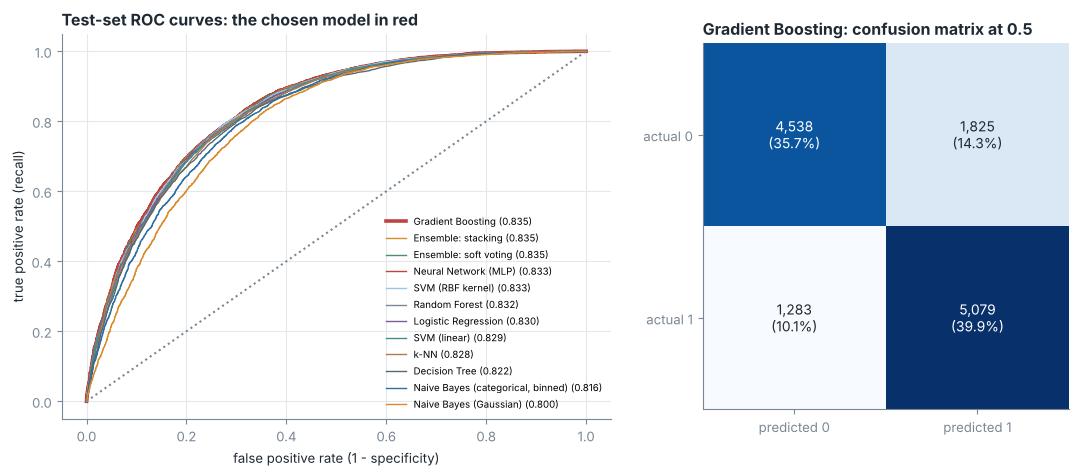

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]
for i, n in enumerate(test_tab.index):
    fpr, tpr, _ = roc_curve(y_test, test_out['scores'][n])
    lw, col = (2.6, RED) if n == CHOSEN else (1, SEQ[i % len(SEQ)])
    ax.plot(fpr, tpr, lw=lw, color=col, label=f'{n} ({test_tab.loc[n, "ROC-AUC"]:.3f})')
ax.plot([0, 1], [0, 1], ':', color=MUTED)
ax.set_xlabel('false positive rate (1 - specificity)'); ax.set_ylabel('true positive rate (recall)')
ax.set_title('Test-set ROC curves: the chosen model in red'); ax.legend(fontsize=7, loc='lower right')
ax = axes[1]
ax.imshow(cm, cmap='Blues'); ax.grid(False)
for (r_, c_), v_ in np.ndenumerate(cm):
    ax.text(c_, r_, f'{v_:,}\n({v_ / cm.sum():.1%})', ha='center', va='center',
            color='white' if v_ > cm.max() / 2 else INK, fontsize=10)
ax.set_xticks([0, 1]); ax.set_xticklabels(['predicted 0', 'predicted 1'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['actual 0', 'actual 1'])
ax.set_title(f'{CHOSEN}: confusion matrix at 0.5')
savefig(fig, 'a3_fig8_test_roc_confusion.png'); plt.show()

## §11 Decision threshold and real-world prevalence

The 0.5 threshold is only a default. The threshold should follow from what the model is *for*. As a screening tool that invites people for a blood-glucose test, a missed diabetic (false negative) costs far more than an unnecessary test (false positive), which argues for a lower threshold and higher recall. The threshold is therefore chosen from **out-of-fold predictions on the training set**, not from the test set, and then simply read off on the test set.

Precision also depends on how common the condition is. On this 50/50 file it looks high, but the real BRFSS prevalence is about 13.9%. Using Bayes' rule, the precision a deployed model would actually achieve is

  precision_real = recall × π / (recall × π + (1 − specificity) × (1 − π)), with π = 0.139.

Recall and specificity do not depend on prevalence, so they carry over unchanged. Precision does not carry over.

In [42]:
def _oof():
    return {'p': cross_val_predict(tuned(CHOSEN), X_train, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]}
p_oof = cached(f'oof_{CHOSEN}', _oof)['p']
PI_REAL = 35_346 / 253_680
def at_threshold(y, p, th):
    pred = (p >= th).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rec, spec = tp / (tp + fn), tn / (tn + fp)
    return {'recall': rec, 'specificity': spec, 'precision (50/50 file)': tp / (tp + fp),
            'precision at 13.9% prevalence': rec * PI_REAL / (rec * PI_REAL + (1 - spec) * (1 - PI_REAL)),
            'accuracy': (tp + tn) / len(y), 'share flagged': pred.mean()}
TH = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
th_oof = pd.DataFrame({th: at_threshold(y_train.values, p_oof, th) for th in TH}).T
th_oof.index.name = 'threshold (training, out-of-fold)'
print(th_oof.round(4).to_string())
# Lowest threshold step that still reaches 85% recall out-of-fold -> fixed before looking at the test set
grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
rec_by = np.array([recall_score(y_train, (p_oof >= t).astype(int)) for t in grid])
TH_SCREEN = float(grid[rec_by >= 0.85].max())
print(f'\nScreening threshold chosen out-of-fold for >= 85% recall: {TH_SCREEN}')
th_test = pd.DataFrame({th: at_threshold(y_test.values, p_test, th) for th in [0.5, TH_SCREEN]}).T
th_test.index.name = 'threshold (applied to TEST)'
print(th_test.round(4).to_string())

                                   recall  specificity  precision (50/50 file)  precision at 13.9% prevalence  accuracy  share flagged
threshold (training, out-of-fold)                                                                                                     
0.2                                0.9622       0.4151                  0.6219                         0.2103    0.6886         0.7736
0.3                                0.9249       0.5240                  0.6602                         0.2393    0.7245         0.7004
0.4                                0.8724       0.6178                  0.6954                         0.2698    0.7451         0.6273
0.5                                0.7996       0.7038                  0.7297                         0.3041    0.7517         0.5479
0.6                                0.6940       0.7900                  0.7677                         0.3486    0.7420         0.4520
0.7                                0.5354       0.8730 

**Reading the result.** For a screening use, the cut-off chosen on out-of-fold training predictions to reach at least 85% recall is **0.43**. Applied to the test set, it catches **85.6%** of diabetics with specificity 0.6546. That means flagging 60.1% of this 50/50 file. At the real-world prevalence of 13.9%, the expected precision is only **0.286**: roughly 2 in 7 flagged people would actually have diabetes or prediabetes. That is acceptable for a cheap first step (inviting someone for a blood-glucose test) but not for anything that treats a flag as a diagnosis, such as insurance pricing.

## §12 How the chosen classifier makes its decisions

Three views, from the most general to the most specific:
1. **Permutation importance** (on the test set): shuffle one attribute at a time and measure how much test AUC drops. It works for any model and is measured on unseen data.
2. **Partial dependence**: how the average predicted probability changes as one attribute changes, with the others held at their observed values.
3. **Logistic regression odds ratios**: the most transparent model's own account, as a cross-check.

**Important limit on interpretation** (raised in the A2 feedback): all three describe *associations the model uses*, not *effects of intervening*. If BMI raises the predicted probability, that means people with higher BMI in this survey are more often diabetic. It does **not** mean that lowering a person's BMI by 5 points would lower their risk by the amount shown. Causation can run in both directions (diabetes and its treatment can change weight and activity), and unmeasured factors (diet, genetics, medication) sit behind several attributes at once. Saying what an intervention would achieve needs a trial or a causal design, not a classifier.

                      AUC drop when shuffled  sd over 10 shuffles
GenHlth                               0.0570               0.0019
BMI                                   0.0380               0.0012
Age                                   0.0260               0.0016
HighBP                                0.0178               0.0013
HighChol                              0.0115               0.0010
CholCheck                             0.0039               0.0004
HvyAlcoholConsump                     0.0030               0.0004
Income                                0.0029               0.0005
HeartDiseaseorAttack                  0.0023               0.0004
Sex_male                              0.0022               0.0003
Stroke                                0.0008               0.0001
DiffWalk                              0.0006               0.0002
MentHlth                              0.0004               0.0002
PhysHlth                              0.0004               0.0001
Education 

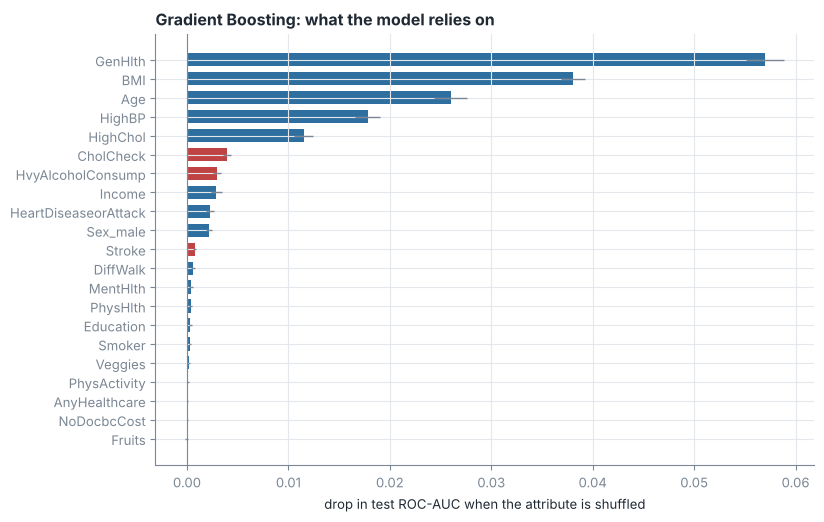

In [43]:
def _pi():
    r = permutation_importance(final_model, X_test, y_test, scoring='roc_auc', n_repeats=10,
                               random_state=RS, n_jobs=-1)
    return {'mean': r.importances_mean, 'std': r.importances_std}
pi = cached(f'perm_importance_{CHOSEN}', _pi)
pi_tab = pd.DataFrame({'AUC drop when shuffled': pi['mean'], 'sd over 10 shuffles': pi['std']},
                      index=FEATURES).sort_values('AUC drop when shuffled', ascending=False)
print(pi_tab.round(4).to_string())

fig, ax = plt.subplots(figsize=(8.5, 5.6))
v = pi_tab.iloc[::-1]
ax.barh(v.index, v.iloc[:, 0], xerr=v.iloc[:, 1], color=[RED if c in LOW_VARIATION else BLUE for c in v.index],
        height=.7, error_kw=dict(ecolor=MUTED, lw=1))
ax.set_xlabel('drop in test ROC-AUC when the attribute is shuffled')
ax.set_title(f'{CHOSEN}: what the model relies on'); ax.axvline(0, color=MUTED, lw=.8)
savefig(fig, 'a3_fig9_permutation_importance.png'); plt.show()

**Reading the result.** Five attributes dominate: GenHlth (AUC drop 0.0570), BMI (0.0380), Age (0.0260), HighBP (0.0178) and HighChol (0.0115). DiffWalk and PhysHlth come out near zero, even though §4 showed each is clearly related to diabetes on its own (0.056 and 0.041 bits). Permutation importance measures what an attribute adds *given the others*, and most of what those two carry is already carried by self-rated health. So an attribute can matter on its own yet add almost nothing once the others are known. CholCheck (0.0039) and heavy drinking (0.0030) rank 6th and 7th, which agrees with §9.

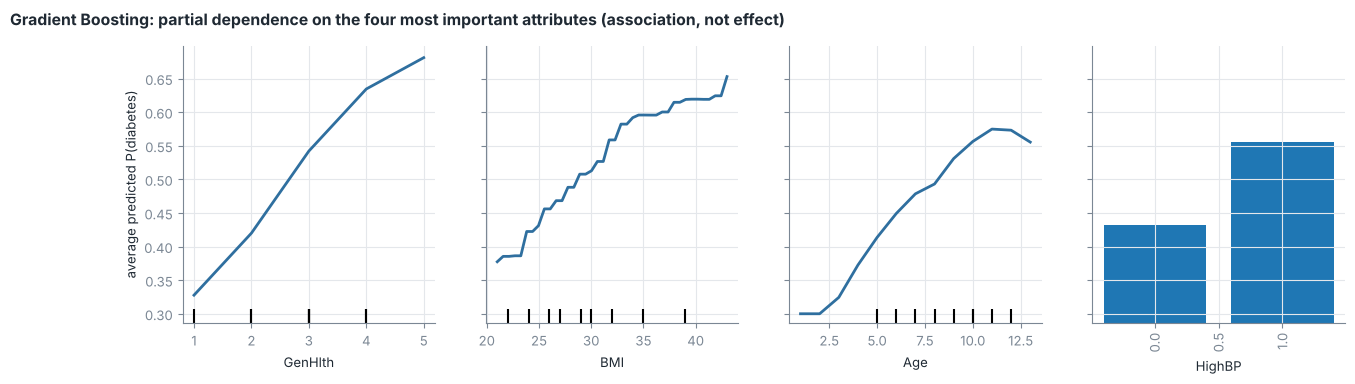

In [44]:
top4 = pi_tab.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
# 3,000 training rows and a 40-point grid keep this to about a minute even for an ensemble
PartialDependenceDisplay.from_estimator(final_model, X_train.sample(3000, random_state=RS).astype(float), top4,
                                        ax=axes, kind='average', grid_resolution=40,
                                        response_method='predict_proba', method='brute',
                                        line_kw={'color': BLUE, 'lw': 2},
                                        categorical_features=[c for c in top4 if c in BINARY] or None)
for a_ in axes: a_.set_ylabel('')
axes[0].set_ylabel('average predicted P(diabetes)')
fig.suptitle(f'{CHOSEN}: partial dependence on the four most important attributes (association, not effect)',
             x=.01, ha='left', fontweight='bold', color=INK)
savefig(fig, 'a3_fig10_partial_dependence.png'); plt.show()

**Reading the result.** The predicted probability rises steadily as self-rated health worsens and as BMI increases. It also rises with age up to roughly bands 11–12 (70–79) and then dips slightly for 80+, which could reflect who survives to be surveyed at that age. It is higher for those told they have high blood pressure. These curves describe the people in the survey. They do **not** say how much one person's risk would change if their BMI or blood pressure were changed.

In [45]:
lr_fit = tuned('Logistic Regression').fit(X_train, y_train)
names = lr_fit.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr_fit.named_steps['clf'].coef_[0], index=names)
odds = pd.DataFrame({'coefficient': coef, 'odds ratio': np.exp(coef)}).sort_values('coefficient', key=abs, ascending=False)
print('Logistic regression, largest effects (numeric inputs are per 1 standard deviation; '
      'one-hot inputs are against the first level):')
print(odds.head(15).round(3).to_string())

Logistic regression, largest effects (numeric inputs are per 1 standard deviation; one-hot inputs are against the first level):
                        coefficient  odds ratio
ord__GenHlth_5                1.997       7.365
ord__GenHlth_4                1.866       6.462
ord__Age_11                   1.809       6.106
ord__Age_12                   1.748       5.746
ord__Age_10                   1.676       5.342
ord__Age_13                   1.611       5.007
ord__Age_9                    1.536       4.648
ord__GenHlth_3                1.423       4.149
bin__CholCheck                1.407       4.082
ord__Age_8                    1.300       3.668
ord__Age_7                    1.230       3.422
ord__Age_6                    0.982       2.669
ord__Age_5                    0.819       2.268
bin__HvyAlcoholConsump       -0.744       0.475
ord__GenHlth_2                0.727       2.068


**Reading the result.** Holding the other attributes fixed, "poor" self-rated health carries 7.4 times the odds of "excellent", and the 70–74 age band 6.1 times the odds of 18–24. CholCheck has an odds ratio of 4.1, and heavy drinking **0.48**, an apparently "protective" association. That is almost certainly not causal. People diagnosed with diabetes are routinely advised to cut alcohol, and heavy drinkers differ from others in many unmeasured ways. It is the clearest example in this data of why a coefficient is not an intervention effect.

### §12.1 A readable rule view: a depth-3 tree

This is not the chosen model. It is a deliberately small tree fitted on the training data so that a non-technical stakeholder can see the main rules. Its own test AUC is printed so it is clear how much accuracy is lost by keeping it this simple.

Depth-3 tree test AUC: 0.7838


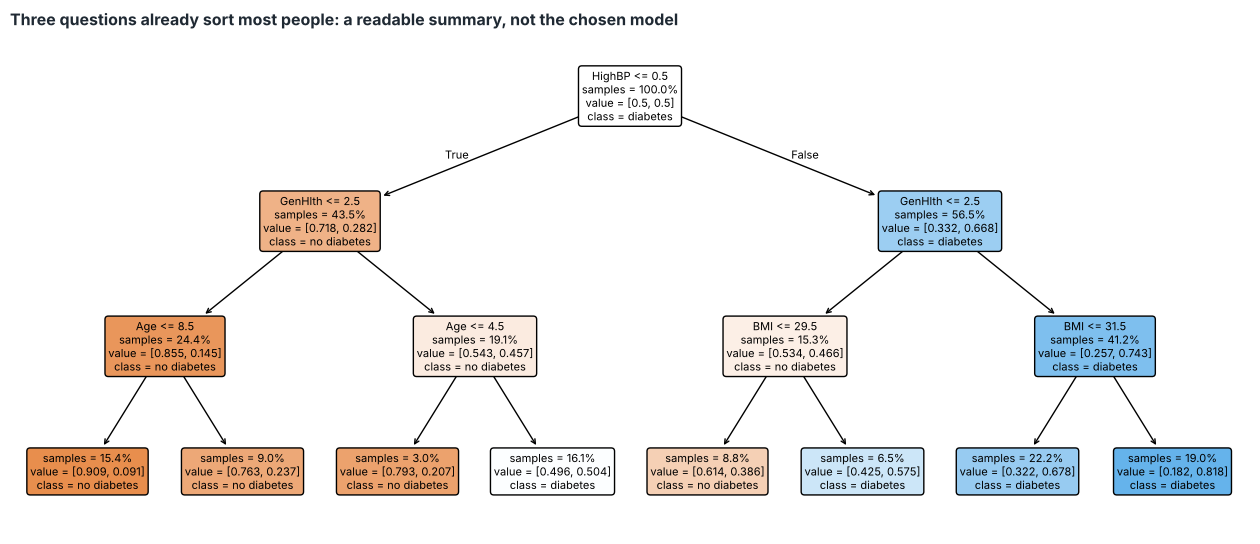

In [46]:
small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=RS).fit(X_train, y_train)
print('Depth-3 tree test AUC:', round(roc_auc_score(y_test, small.predict_proba(X_test)[:, 1]), 4))
fig, ax = plt.subplots(figsize=(16, 6.5)); ax.grid(False)
plot_tree(small, feature_names=FEATURES, class_names=['no diabetes', 'diabetes'], filled=True,
          proportion=True, impurity=False, rounded=True, fontsize=8, ax=ax)
ax.set_title('Three questions already sort most people: a readable summary, not the chosen model')
savefig(fig, 'a3_fig11_depth3_tree.png'); plt.show()

**Reading the result.** Three questions take a depth-3 tree to AUC 0.7838, against 0.8354 for the chosen model. The first split is high blood pressure, then self-rated health, then age or BMI. At one end, people *without* high blood pressure, rating their health good or better (GenHlth ≤ 2) and under 60 (15.4% of rows) are 9.1% diabetic. At the other, people *with* high blood pressure, rating their health good or worse and with BMI above 31.5 (19.0% of rows) are 81.8% diabetic. The tree is useful for explaining the model to a non-technical audience, but gradient boosting does the actual predicting.

## §13 Export of every number the report quotes

In [47]:
out_xlsx = os.path.join(OUT_DIR, 'a3_results_26314132.xlsx')
with pd.ExcelWriter(out_xlsx) as xw:
    summary.assign(**{'tuned parameters': summary['tuned parameters'].astype(str)}).to_excel(xw, sheet_name='cv_summary')
    sig.to_excel(xw, sheet_name='significance_vs_leader')
    test_tab.to_excel(xw, sheet_name='test_all_models')
    ci.to_excel(xw, sheet_name='test_chosen_CI')
    th_oof.to_excel(xw, sheet_name='thresholds_oof'); th_test.to_excel(xw, sheet_name='thresholds_test')
    drop_tab.to_excel(xw, sheet_name='drop_low_variation')
    pi_tab.to_excel(xw, sheet_name='permutation_importance')
    prof_tab.to_excel(xw, sheet_name='class_profile_MI')
    odds.to_excel(xw, sheet_name='lr_odds_ratios')
    scale_demo.to_excel(xw, sheet_name='scaler_demo')
    for c, t in bin_tables.items(): t.to_excel(xw, sheet_name=f'bins_{c}')
    for n, r in REGISTRY.items():
        r['folds'].to_excel(xw, sheet_name=('folds_' + n)[:31].replace(':', '').replace('/', ''))
print('Written:', out_xlsx)
print('Figures:', sorted(os.listdir(FIG_DIR)))

Written: /tmp/claude-0/-home-claude/c9b9a1fe-4c12-534d-95e5-eee87b3c50aa/scratchpad/run/outputs/a3_results_26314132.xlsx
Figures: ['a3_fig10_partial_dependence.png', 'a3_fig11_depth3_tree.png', 'a3_fig1_mutual_information.png', 'a3_fig2_knn_k_curve.png', 'a3_fig3_tree_depth_curve.png', 'a3_fig4_rf_oob.png', 'a3_fig5_cv_comparison_all.png', 'a3_fig6_cv_comparison_zoom.png', 'a3_fig7_learning_curve.png', 'a3_fig8_test_roc_confusion.png', 'a3_fig9_permutation_importance.png']
